In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("clean_final_data.csv")

print(df.shape)
display(df.head())

(49222, 17)


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,2025-08-28,2003,4.0,10.0,Gateway,Completed,36.0,Qom,2024-03-05,Regular,USB-C Cable,Accessories,9.0,32.0,32.0
1,500002,107935,2024-05-31,2014,1.0,10.0,Wallet,Completed,49.0,Kerman,2025-06-04,Regular,Backpack,Accessories,42.0,38.0,38.0
2,500003,105141,2025-08-10,2002,1.0,20.0,CardToCard,Completed,36.0,Tehran,2025-10-19,Regular,Mechanical Keyboard,Electronics,62.0,50.0,50.0
3,500004,108780,2024-10-11,2012,1.0,10.0,Gateway,Completed,45.0,Shiraz,2023-12-07,Regular,Office Chair,Home Office,180.0,162.0,162.0
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed,24.0,Karaj,2023-12-02,Regular,Phone Case,Accessories,14.0,28.0,28.0


In [113]:

print("MISSING VALUES")
print(df.isnull().sum())


print("\nDUPLICATE ROWS")
print(df.duplicated().sum())


numeric_cols = df.select_dtypes(include="number").columns

print("\nNEGATIVE VALUES")
print(df[numeric_cols].lt(0).sum())


print("\nORDER STATUS COUNTS")
print(df["Status"].value_counts(dropna=False))

print("\nPAYMENT METHOD COUNTS")
print(df["PaymentMethod"].value_counts(dropna=False))

MISSING VALUES
OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity           0
Discount           0
PaymentMethod      0
Status             0
Age                0
City               0
SignupDate         0
CustomerSegment    0
ProductName        0
Category           0
UnitPrice          0
Sales              0
OrderValue         0
dtype: int64

DUPLICATE ROWS
0

NEGATIVE VALUES
OrderID        0
CustomerID     0
ProductID      0
Quantity      19
Discount       0
Age            0
UnitPrice      0
Sales         19
OrderValue    19
dtype: int64

ORDER STATUS COUNTS
Status
Completed    45276
Cancelled     2438
Returned      1508
Name: count, dtype: int64

PAYMENT METHOD COUNTS
PaymentMethod
Gateway       23894
CardToCard    11744
Wallet         8661
Cash           4923
Name: count, dtype: int64


In [114]:

df["ExpectedSales"] = (
    df["Quantity"]
    * df["UnitPrice"]
    * (1 - df["Discount"] / 100)
)


df["SalesDifference"] = (
    df["Sales"] - df["ExpectedSales"]
).round(2)

print("Rows with sales calculation differences:")
print((df["SalesDifference"].abs() > 0.01).sum())

display(
    df[
        ["Quantity", "UnitPrice", "Discount",
         "Sales", "ExpectedSales", "SalesDifference"]
    ].head(10)
)

Rows with sales calculation differences:
28012


,Quantity,UnitPrice,Discount,Sales,ExpectedSales,SalesDifference
0,4.0,9.0,10.0,32.0,32.40,-0.40
1,1.0,42.0,10.0,38.0,37.80,0.20
2,1.0,62.0,20.0,50.0,49.60,0.40
3,1.0,180.0,10.0,162.0,162.00,0.00
4,2.0,14.0,0.0,28.0,28.00,0.00
5,4.0,32.0,0.0,128.0,128.00,0.00
6,1.0,11.0,5.0,10.0,10.45,-0.45
7,1.0,42.0,0.0,42.0,42.00,0.00
8,1.0,35.0,10.0,32.0,31.50,0.50
9,2.0,42.0,5.0,80.0,79.80,0.20


In [115]:
# Inspect rows with negative quantities or sales
negative_rows = df[
    (df["Quantity"] < 0) |
    (df["Sales"] < 0) |
    (df["OrderValue"] < 0)
]

display(
    negative_rows[
        ["OrderID", "OrderDate", "Quantity", "Discount",
         "Status", "UnitPrice", "Sales", "OrderValue"]
    ]
)

print("Total suspicious rows:", len(negative_rows))

print("\nStatus of suspicious rows:")
print(negative_rows["Status"].value_counts())

,OrderID,OrderDate,Quantity,Discount,Status,UnitPrice,Sales,OrderValue
406,500414,2026-06-27,-1.0,0.0,Completed,11.0,-11.0,-11.0
2956,503005,2025-05-01,-2.0,0.0,Completed,9.0,-18.0,-18.0
3362,503416,2025-04-03,-1.0,10.0,Completed,7.0,-6.0,-6.0
3895,503960,2024-04-22,-1.0,5.0,Completed,9.0,-9.0,-9.0
9055,509199,2024-11-28,-2.0,0.0,Completed,85.0,-170.0,-170.0
9946,510103,2025-09-21,-2.0,5.0,Completed,68.0,-129.0,-129.0
10861,511036,2025-09-28,-1.0,10.0,Completed,7.0,-6.0,-6.0
12618,512820,2024-05-11,-1.0,5.0,Completed,18.0,-17.0,-17.0
13110,513318,2024-09-04,-1.0,0.0,Completed,42.0,-42.0,-42.0
19262,519585,2025-09-11,-1.0,0.0,Completed,7.0,-7.0,-7.0


Total suspicious rows: 19

Status of suspicious rows:
Status
Completed    18
Cancelled     1
Name: count, dtype: int64


In [116]:
# Hypothesis: round discounted unit price before multiplying quantity
df["TestSales"] = (
    (df["UnitPrice"] * (1 - df["Discount"] / 100)).round()
    * df["Quantity"]
)

df["TestDifference"] = (
    df["Sales"] - df["TestSales"]
).round(2)

print(
    "Rows that match this formula:",
    (df["TestDifference"].abs() <= 0.01).sum()
)

print(
    "Rows that do not match:",
    (df["TestDifference"].abs() > 0.01).sum()
)

display(
    df.loc[
        df["TestDifference"].abs() > 0.01,
        ["Quantity", "UnitPrice", "Discount",
         "Sales", "TestSales", "TestDifference"]
    ].head(10)
)

Rows that match this formula: 39338
Rows that do not match: 9884


,Quantity,UnitPrice,Discount,Sales,TestSales,TestDifference
10,3.0,35.0,30.0,74.0,72.0,2.0
12,3.0,28.0,10.0,76.0,75.0,1.0
32,3.0,75.0,5.0,214.0,213.0,1.0
34,5.0,14.0,10.0,63.0,65.0,-2.0
36,4.0,18.0,15.0,61.0,60.0,1.0
37,5.0,7.0,5.0,33.0,35.0,-2.0
38,4.0,32.0,10.0,115.0,116.0,-1.0
39,2.0,55.0,30.0,77.0,76.0,1.0
43,2.0,11.0,5.0,21.0,20.0,1.0
50,3.0,7.0,10.0,19.0,18.0,1.0


In [117]:
# Load the original source files
orders_raw = pd.read_csv("orders.csv")
payments_raw = pd.read_csv("payments.csv")
products_raw = pd.read_csv("products.csv")
customers_raw = pd.read_csv("customers.csv")

# 1. Check negative quantities in original orders
print("Negative quantities in original orders:")
display(
    orders_raw[orders_raw["Quantity"] < 0]
)

# 2. Compare suspicious order IDs with source orders
negative_ids = negative_rows["OrderID"].tolist()

print("\nMatching source orders:")
display(
    orders_raw[orders_raw["OrderID"].isin(negative_ids)]
)

# 3. Check payment status for suspicious orders
print("\nPayments for suspicious orders:")
display(
    payments_raw[
        payments_raw["OrderID"].isin(negative_ids)
    ]
)

# 4. Check whether any original order IDs are duplicated
print("\nDuplicate order IDs in source:")
print(orders_raw["OrderID"].duplicated().sum())

# 5. Check orders missing from the cleaned dataset
missing_ids = set(orders_raw["OrderID"]) - set(df["OrderID"])

print("\nSource orders not represented in cleaned data:")
print(len(missing_ids))

Negative quantities in original orders:


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status
413,500414,105862,2026-06-27,2017,-1.0,0.00,Gateway,Completed
3004,503005,100177,2025-05-01,2003,-2.0,0.00,Gateway,Completed
3415,503416,106363,2025-04-03,2013,-1.0,0.10,Gateway,Completed
3959,503960,103089,2024-04-22,2003,-1.0,0.05,CardToCard,Completed
9198,509199,109651,2024-11-28,2018,-2.0,0.00,CardToCard,Completed
10102,510103,106518,2025-09-21,2020,-2.0,0.05,Gateway,Completed
11035,511036,102603,2025-09-28,2013,-1.0,0.10,Gateway,Completed
12819,512820,101380,2024-05-11,2001,-1.0,0.05,Cash,Completed
13317,513318,106335,2024-09-04,2014,-1.0,0.00,Gateway,Completed
19584,519585,104098,2025-09-11,2013,-1.0,0.00,Gateway,Completed



Matching source orders:


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status
413,500414,105862,2026-06-27,2017,-1.0,0.00,Gateway,Completed
3004,503005,100177,2025-05-01,2003,-2.0,0.00,Gateway,Completed
3415,503416,106363,2025-04-03,2013,-1.0,0.10,Gateway,Completed
3959,503960,103089,2024-04-22,2003,-1.0,0.05,CardToCard,Completed
9198,509199,109651,2024-11-28,2018,-2.0,0.00,CardToCard,Completed
10102,510103,106518,2025-09-21,2020,-2.0,0.05,Gateway,Completed
11035,511036,102603,2025-09-28,2013,-1.0,0.10,Gateway,Completed
12819,512820,101380,2024-05-11,2001,-1.0,0.05,Cash,Completed
13317,513318,106335,2024-09-04,2014,-1.0,0.00,Gateway,Completed
19584,519585,104098,2025-09-11,2013,-1.0,0.00,Gateway,Completed



Payments for suspicious orders:


,PaymentID,OrderID,PaymentDate,PaymentStatus
413,800414,500414,2026-06-27,Paid
3004,803005,503005,2025-05-01,Paid
3415,803416,503416,2025-04-03,Paid
3959,803960,503960,2024-04-22,Paid
9198,809199,509199,2024-11-28,Paid
10102,810103,510103,2025-09-21,Paid
11035,811036,511036,2025-09-28,Paid
12819,812820,512820,2024-05-11,Paid
13317,813318,513318,2024-09-04,Paid
19584,819585,519585,2025-09-11,Paid



Duplicate order IDs in source:
120

Source orders not represented in cleaned data:
778


In [118]:
# 1. Find all repeated OrderIDs in the original orders file
duplicate_orders = orders_raw[
    orders_raw["OrderID"].duplicated(keep=False)
].sort_values("OrderID")

print("Rows with repeated OrderIDs:", len(duplicate_orders))
print("Unique repeated OrderIDs:",
      duplicate_orders["OrderID"].nunique())

display(duplicate_orders.head(20))


# 2. Check whether OrderIDs are repeated in the cleaned dataset
print("\nRepeated OrderIDs in cleaned data:")
print(df["OrderID"].duplicated().sum())


# 3. Inspect the first 20 original orders missing from cleaned data
missing_order_details = orders_raw[
    orders_raw["OrderID"].isin(missing_ids)
]

print("\nFirst 20 missing orders:")
display(missing_order_details.head(20))


# 4. Check whether the missing orders have valid customer and product IDs
print("\nMissing-order customer IDs absent from customers:")
print(
    (~missing_order_details["CustomerID"].isin(
        customers_raw["CustomerID"]
    )).sum()
)

print("\nMissing-order product IDs absent from products:")
print(
    (~missing_order_details["ProductID"].isin(
        products_raw["ProductID"]
    )).sum()
)

Rows with repeated OrderIDs: 240
Unique repeated OrderIDs: 120


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status
199,500200,104768,2025-08-03,2008,2.0,0.10,CardToCard,Completed
50002,500200,104768,2025-08-03,2008,2.0,0.10,CardToCard,Completed
725,500726,102977,2025-11-26,2013,2.0,0.10,Wallet,Returned
50061,500726,102977,2025-11-26,2013,2.0,0.10,Wallet,Returned
50022,500822,100897,2026-01-03,2003,1.0,0.00,Gateway,Completed
821,500822,100897,2026-01-03,2003,1.0,0.00,Gateway,Completed
1414,501415,108793,2025-02-28,2004,1.0,0.10,Wallet,Completed
50013,501415,108793,2025-02-28,2004,1.0,0.10,Wallet,Completed
50092,501813,108688,2025-12-20,2014,2.0,0.10,NaN,Completed
1812,501813,108688,2025-12-20,2014,2.0,0.10,NaN,Completed



Repeated OrderIDs in cleaned data:
0

First 20 missing orders:


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status
35,500036,103010,2025-10-12,2017,2.0,0.20,Wallet,Completed
92,500093,104739,2025-03-23,2018,2.0,0.10,Gateway,Completed
143,500144,101874,2025-04-27,2016,1.0,0.00,CardToCard,Completed
209,500210,107838,2024-07-18,2011,1.0,0.00,Gateway,Completed
218,500219,108532,2024-04-11,2011,1.0,0.00,Wallet,Completed
404,500405,106155,2025-06-24,2006,4.0,0.00,Wallet,Completed
409,500410,105410,2024-10-11,2008,1.0,0.00,Gateway,Completed
433,500434,105631,2024-01-31,2003,1.0,0.00,Cash,Completed
503,500504,100238,2024-12-22,2010,1.0,0.00,Gateway,Completed
884,500885,105741,2024-11-26,2019,1.0,0.30,Cash,Completed



Missing-order customer IDs absent from customers:
30

Missing-order product IDs absent from products:
0


In [119]:
# 1. Check whether repeated order IDs are exact duplicates
print("Exact duplicate rows in orders.csv:",
      orders_raw.duplicated().sum())

# Check whether each repeated OrderID has identical values
duplicate_groups = (
    duplicate_orders.groupby("OrderID")
    .nunique()
)

print("\nRepeated OrderIDs with differing field values:")
print((duplicate_groups > 1).any(axis=1).sum())


# 2. Investigate the 778 missing order IDs
missing_details = orders_raw[
    orders_raw["OrderID"].isin(missing_ids)
].copy()

# Check references to customers, products and payments
missing_details["CustomerExists"] = (
    missing_details["CustomerID"].isin(customers_raw["CustomerID"])
)

missing_details["ProductExists"] = (
    missing_details["ProductID"].isin(products_raw["ProductID"])
)

missing_details["PaymentExists"] = (
    missing_details["OrderID"].isin(payments_raw["OrderID"])
)

print("\nMissing-order validation:")
print("Total missing order rows:", len(missing_details))
print("Customer references missing:",
      (~missing_details["CustomerExists"]).sum())
print("Product references missing:",
      (~missing_details["ProductExists"]).sum())
print("Payment records missing:",
      (~missing_details["PaymentExists"]).sum())

print("\nStatus of missing orders:")
print(missing_details["Status"].value_counts(dropna=False))

print("\nPayment record availability:")
print(missing_details["PaymentExists"].value_counts())


# 3. Display a small sample for inspection
display(missing_details.head(10))

Exact duplicate rows in orders.csv: 120

Repeated OrderIDs with differing field values:
0

Missing-order validation:
Total missing order rows: 781
Customer references missing: 30
Product references missing: 0
Payment records missing: 0

Status of missing orders:
Status
Completed    723
Cancelled     34
Returned      24
Name: count, dtype: int64

Payment record availability:
PaymentExists
True    781
Name: count, dtype: int64


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,CustomerExists,ProductExists,PaymentExists
35,500036,103010,2025-10-12,2017,2.0,0.2,Wallet,Completed,True,True,True
92,500093,104739,2025-03-23,2018,2.0,0.1,Gateway,Completed,True,True,True
143,500144,101874,2025-04-27,2016,1.0,0.0,CardToCard,Completed,True,True,True
209,500210,107838,2024-07-18,2011,1.0,0.0,Gateway,Completed,True,True,True
218,500219,108532,2024-04-11,2011,1.0,0.0,Wallet,Completed,True,True,True
404,500405,106155,2025-06-24,2006,4.0,0.0,Wallet,Completed,True,True,True
409,500410,105410,2024-10-11,2008,1.0,0.0,Gateway,Completed,True,True,True
433,500434,105631,2024-01-31,2003,1.0,0.0,Cash,Completed,True,True,True
503,500504,100238,2024-12-22,2010,1.0,0.0,Gateway,Completed,True,True,True
884,500885,105741,2024-11-26,2019,1.0,0.3,Cash,Completed,True,True,True


In [120]:
# 1. Compare source and cleaned dataset sizes
print("Original order rows:", len(orders_raw))
print("Exact duplicate source rows:", orders_raw.duplicated().sum())
print("Unique source orders:", orders_raw["OrderID"].nunique())

print("\nCleaned dataset rows:", len(df))
print("Unique cleaned orders:", df["OrderID"].nunique())


# 2. Identify IDs missing from the cleaned dataset
source_ids = set(orders_raw["OrderID"])
clean_ids = set(df["OrderID"])

missing_ids = source_ids - clean_ids

print("\nUnique IDs missing from cleaned data:", len(missing_ids))

# Count source rows belonging to missing IDs
missing_details = orders_raw[
    orders_raw["OrderID"].isin(missing_ids)
].copy()

print("Source rows belonging to missing IDs:", len(missing_details))


# 3. Check whether any missing IDs were duplicated in source
print(
    "\nMissing IDs that were duplicated in source:",
    missing_details["OrderID"].duplicated().sum()
)


# 4. Summarise missing orders by status
print("\nMissing orders by status:")
print(missing_details["Status"].value_counts(dropna=False))


# 5. Check invalid customer references
valid_customer_ids = set(customers_raw["CustomerID"])

print(
    "\nRows with missing customer references:",
    (~missing_details["CustomerID"].isin(valid_customer_ids)).sum()
)

Original order rows: 50120
Exact duplicate source rows: 120
Unique source orders: 50000

Cleaned dataset rows: 49222
Unique cleaned orders: 49222

Unique IDs missing from cleaned data: 778
Source rows belonging to missing IDs: 781

Missing IDs that were duplicated in source: 3

Missing orders by status:
Status
Completed    723
Cancelled     34
Returned      24
Name: count, dtype: int64

Rows with missing customer references: 30


In [121]:
# 1. Check missing values in the original source files
print("MISSING VALUES IN ORIGINAL FILES")

for name, data in {
    "Orders": orders_raw,
    "Customers": customers_raw,
    "Payments": payments_raw,
    "Products": products_raw
}.items():
    print(f"\n{name}:")
    print(data.isnull().sum())


# 2. Check missing values in the original orders
print("\nORDERS WITH MISSING VALUES")
print(orders_raw.isnull().sum())


# 3. Check missing values in customer records
print("\nCUSTOMER RECORDS WITH MISSING VALUES")
display(customers_raw[customers_raw.isnull().any(axis=1)].head(10))


# 4. Check whether the missing orders reference
# customers with missing information
customer_details = missing_details.merge(
    customers_raw,
    on="CustomerID",
    how="left",
    indicator=True,
    suffixes=("_order", "_customer")
)

print("\nMISSING ORDERS AFTER CUSTOMER JOIN")
print("Total rows:", len(customer_details))
print("Rows with no matching customer:",
      (customer_details["_merge"] == "left_only").sum())

print("\nMissing customer information among matched records:")
matched_customers = customer_details[
    customer_details["_merge"] == "both"
]

print(matched_customers.isnull().sum())

MISSING VALUES IN ORIGINAL FILES

Orders:
OrderID            0
CustomerID         0
OrderDate         35
ProductID          0
Quantity          80
Discount         221
PaymentMethod    452
Status             0
dtype: int64

Customers:
CustomerID           0
Age                180
City               119
SignupDate           0
CustomerSegment      0
dtype: int64

Payments:
PaymentID         0
OrderID           0
PaymentDate      35
PaymentStatus     0
dtype: int64

Products:
ProductID      0
ProductName    0
Category       0
UnitPrice      0
dtype: int64

ORDERS WITH MISSING VALUES
OrderID            0
CustomerID         0
OrderDate         35
ProductID          0
Quantity          80
Discount         221
PaymentMethod    452
Status             0
dtype: int64

CUSTOMER RECORDS WITH MISSING VALUES


,CustomerID,Age,City,SignupDate,CustomerSegment
9,100010,NaN,Mashhad,2024-06-24,New
10,100011,NaN,Tehran,2025-08-11,Regular
16,100017,NaN,Isfahan,2024-12-08,Regular
62,100063,35.0,NaN,2025-07-20,New
124,100125,59.0,NaN,2025-01-20,Regular
153,100154,NaN,Tehran,2024-09-08,Regular
160,100161,NaN,Kerman,2025-05-23,Regular
186,100187,25.0,NaN,2024-12-30,New
211,100212,NaN,Tehran,2024-12-14,Regular
230,100231,NaN,Qom,2025-08-15,New



MISSING ORDERS AFTER CUSTOMER JOIN
Total rows: 781
Rows with no matching customer: 30

Missing customer information among matched records:
OrderID              0
CustomerID           0
OrderDate           35
ProductID            0
Quantity            80
Discount             5
PaymentMethod        8
Status               0
Age                 21
City               638
SignupDate           0
CustomerSegment      0
_merge               0
dtype: int64


In [122]:

# Step 4.10: Investigate missing orders

# Create flags for data-quality issues
customer_details["MissingOrderDate"] = customer_details["OrderDate"].isna()
customer_details["MissingQuantity"] = customer_details["Quantity"].isna()
customer_details["MissingDiscount"] = customer_details["Discount"].isna()
customer_details["MissingPaymentMethod"] = customer_details["PaymentMethod"].isna()
customer_details["MissingAge"] = customer_details["Age"].isna()
customer_details["MissingCity"] = customer_details["City"].isna()

customer_details["CustomerNotFound"] = (
    customer_details["_merge"] == "left_only"
)

issue_columns = [
    "MissingOrderDate",
    "MissingQuantity",
    "MissingDiscount",
    "MissingPaymentMethod",
    "MissingAge",
    "MissingCity",
    "CustomerNotFound"
]

print("ORDERS WITH EACH DATA-QUALITY ISSUE")
print(
    customer_details[issue_columns]
    .sum()
    .sort_values(ascending=False)
)

# Count how many issues each row has
customer_details["IssueCount"] = (
    customer_details[issue_columns].sum(axis=1)
)

print("\nNUMBER OF ISSUES PER ROW")
print(
    customer_details["IssueCount"]
    .value_counts()
    .sort_index()
)

print("\nROWS WITH NO FLAGGED ISSUES")
print((customer_details["IssueCount"] == 0).sum())


ORDERS WITH EACH DATA-QUALITY ISSUE
MissingCity             668
MissingQuantity          80
MissingAge               51
MissingOrderDate         35
CustomerNotFound         30
MissingPaymentMethod      9
MissingDiscount           5
dtype: int64

NUMBER OF ISSUES PER ROW
IssueCount
1    715
2     36
3     29
4      1
Name: count, dtype: int64

ROWS WITH NO FLAGGED ISSUES
0


In [123]:

# Step 4.11: Check missing City across the original orders

print("ORIGINAL ORDERS")
print("Total rows:", len(orders_raw))

# Join original orders with customer information
orders_with_customers = orders_raw.merge(
    customers_raw,
    on="CustomerID",
    how="left",
    indicator=True
)

print("\nORIGINAL ORDERS AFTER CUSTOMER JOIN")
print("Total rows:", len(orders_with_customers))
print(
    "Rows with missing City:",
    orders_with_customers["City"].isna().sum()
)

# Compare missing City for excluded and retained order IDs
clean_order_ids = set(df["OrderID"])
excluded_mask = ~orders_with_customers["OrderID"].isin(clean_order_ids)

print("\nEXCLUDED SOURCE ROWS")
print("Rows:", excluded_mask.sum())
print(
    "Rows with missing City:",
    orders_with_customers.loc[excluded_mask, "City"].isna().sum()
)

print("\nRETAINED SOURCE ROWS")
retained_mask = ~excluded_mask
print("Rows:", retained_mask.sum())
print(
    "Rows with missing City:",
    orders_with_customers.loc[retained_mask, "City"].isna().sum()
)


ORIGINAL ORDERS
Total rows: 50120

ORIGINAL ORDERS AFTER CUSTOMER JOIN
Total rows: 50120
Rows with missing City: 668

EXCLUDED SOURCE ROWS
Rows: 781
Rows with missing City: 668

RETAINED SOURCE ROWS
Rows: 49339
Rows with missing City: 0


In [124]:

# Step 4.12: Classify excluded source rows

excluded_rows = orders_with_customers.loc[excluded_mask].copy()

print("EXCLUDED ROW CLASSIFICATION")

print(
    excluded_rows["City"]
    .isna()
    .value_counts()
    .rename(index={True: "Missing City", False: "City Present"})
)

print("\nEXCLUDED ROWS WITH CITY PRESENT")

display(
    excluded_rows[
        excluded_rows["City"].notna()
    ][
        ["OrderID", "CustomerID", "OrderDate", "Quantity",
         "Discount", "PaymentMethod", "Status", "City", "Age"]
    ].head(20)
)

print("\nMISSING VALUES IN EXCLUDED ROWS WITH CITY PRESENT")

display(
    excluded_rows[
        excluded_rows["City"].notna()
    ].isnull().sum().sort_values(ascending=False)
)


EXCLUDED ROW CLASSIFICATION
City
Missing City    668
City Present    113
Name: count, dtype: int64

EXCLUDED ROWS WITH CITY PRESENT


,OrderID,CustomerID,OrderDate,Quantity,Discount,PaymentMethod,Status,City,Age
1725,501726,103832,2024-03-17,NaN,0.05,Gateway,Completed,Shiraz,27.0
2355,502356,102438,NaN,4.0,0.00,Gateway,Completed,Mashhad,50.0
2664,502665,106550,2025-06-24,NaN,0.10,CardToCard,Completed,Tabriz,51.0
3521,503522,105703,2024-05-08,NaN,0.00,Wallet,Completed,Tehran,31.0
4801,504802,104924,2024-08-18,NaN,0.30,Wallet,Completed,Tehran,50.0
4926,504927,102111,NaN,1.0,0.00,Gateway,Completed,Kerman,31.0
5312,505313,107357,2024-02-07,NaN,0.05,Gateway,Completed,Rasht,32.0
5432,505433,101980,2025-05-07,NaN,0.05,Wallet,Completed,Karaj,56.0
5564,505565,103942,NaN,2.0,0.15,CardToCard,Completed,Tehran,32.0
6267,506268,104260,NaN,1.0,0.05,Cash,Completed,Isfahan,19.0



MISSING VALUES IN EXCLUDED ROWS WITH CITY PRESENT


,0
Quantity,79
OrderDate,34
PaymentMethod,1
CustomerID,0
OrderID,0
ProductID,0
Discount,0
Status,0
Age,0
City,0


In [125]:

# Step 4.13: Test a possible cleaning rule

required_order_fields = [
    "OrderDate",
    "Quantity",
    "Discount",
    "PaymentMethod"
]

# Identify source rows with complete order fields
complete_order_mask = orders_raw[required_order_fields].notna().all(axis=1)

# Identify customers with a non-missing City
valid_customer_ids = set(
    customers_raw.loc[
        customers_raw["City"].notna(), "CustomerID"
    ]
)

valid_customer_mask = orders_raw["CustomerID"].isin(valid_customer_ids)

# Apply both conditions
candidate_mask = complete_order_mask & valid_customer_mask

candidate_orders = orders_raw.loc[candidate_mask].drop_duplicates()

print("Original order rows:", len(orders_raw))
print("Rows with complete required order fields:", complete_order_mask.sum())
print("Rows with a valid customer City:", valid_customer_mask.sum())
print("Rows meeting both conditions before deduplication:", candidate_mask.sum())
print("Unique candidate orders:", candidate_orders["OrderID"].nunique())
print("Unique orders in clean dataset:", df["OrderID"].nunique())

candidate_ids = set(candidate_orders["OrderID"])
clean_ids = set(df["OrderID"])

print("\nCandidate orders missing from clean dataset:", len(candidate_ids - clean_ids))
print("Clean orders absent from candidate set:", len(clean_ids - candidate_ids))


Original order rows: 50120
Rows with complete required order fields: 49336
Rows with a valid customer City: 49452
Rows meeting both conditions before deduplication: 48683
Unique candidate orders: 48569
Unique orders in clean dataset: 49222

Candidate orders missing from clean dataset: 0
Clean orders absent from candidate set: 653


In [126]:

# Step 4.14: Investigate cleaned orders outside our proposed rule

extra_ids = clean_ids - candidate_ids

extra_orders = orders_raw[
    orders_raw["OrderID"].isin(extra_ids)
].copy()

# Attach customer details to identify missing customer information
extra_orders = extra_orders.merge(
    customers_raw,
    on="CustomerID",
    how="left",
    indicator=True
)

print("Additional cleaned orders:", len(extra_ids))
print("Original source rows for these orders:", len(extra_orders))

print("\nMissing values in these source orders:")
print(
    extra_orders[
        [
            "OrderDate", "Quantity", "Discount",
            "PaymentMethod", "Age", "City"
        ]
    ].isna().sum().sort_values(ascending=False)
)

print("\nCustomer match status:")
print(extra_orders["_merge"].value_counts())

print("\nSample of additional cleaned orders:")
display(
    extra_orders[
        [
            "OrderID", "CustomerID", "OrderDate",
            "Quantity", "Discount", "PaymentMethod",
            "Status", "Age", "City"
        ]
    ].head(15)
)


Additional cleaned orders: 653
Original source rows for these orders: 656

Missing values in these source orders:
PaymentMethod    443
Discount         216
Age               16
OrderDate          0
Quantity           0
City               0
dtype: int64

Customer match status:
_merge
both          656
left_only       0
right_only      0
Name: count, dtype: int64

Sample of additional cleaned orders:


,OrderID,CustomerID,OrderDate,Quantity,Discount,PaymentMethod,Status,Age,City
0,500045,100241,2025-06-18,2.0,0.05,NaN,Completed,24.0,Tehran
1,500114,107642,2025-11-30,3.0,0.00,NaN,Completed,54.0,Shiraz
2,500116,102851,2026-06-04,1.0,0.05,NaN,Completed,27.0,Shiraz
3,500120,104593,2026-01-19,5.0,0.00,NaN,Completed,21.0,Rasht
4,500134,100871,2025-02-02,1.0,NaN,CardToCard,Completed,39.0,Tabriz
5,500174,106216,2025-03-15,1.0,0.10,NaN,Completed,NaN,Tehran
6,500199,105852,2025-04-07,2.0,0.00,NaN,Completed,46.0,Isfahan
7,500247,102218,2025-07-14,3.0,NaN,Cash,Completed,65.0,Mashad
8,500283,105484,2025-01-27,2.0,0.10,NaN,Completed,58.0,Tabriz
9,500305,102046,2025-08-02,2.0,0.20,NaN,Completed,65.0,Kerman


In [127]:

# Step 4.15: Compare source and cleaned records

comparison = orders_raw[
    orders_raw["OrderID"].isin(extra_ids)
].drop_duplicates(subset="OrderID").merge(
    df,
    on="OrderID",
    how="inner",
    suffixes=("_source", "_clean")
)

columns_to_compare = [
    ("PaymentMethod_source", "PaymentMethod_clean"),
    ("Discount_source", "Discount_clean"),
    ("Quantity_source", "Quantity_clean"),
    ("OrderDate_source", "OrderDate_clean")
]

for source_col, clean_col in columns_to_compare:
    if source_col in comparison.columns and clean_col in comparison.columns:
        print(f"\n{source_col} vs {clean_col}")
        print(
            "Source missing, cleaned filled:",
            (
                comparison[source_col].isna()
                & comparison[clean_col].notna()
            ).sum()
        )
        print(
            "Source and cleaned values differ:",
            (
                comparison[source_col].notna()
                & comparison[clean_col].notna()
                & (
                    comparison[source_col].astype(str)
                    != comparison[clean_col].astype(str)
                )
            ).sum()
        )

print("\nSAMPLE COMPARISON")
display(
    comparison[
        [
            "OrderID",
            "PaymentMethod_source", "PaymentMethod_clean",
            "Discount_source", "Discount_clean",
            "Quantity_source", "Quantity_clean",
            "OrderDate_source", "OrderDate_clean"
        ]
    ].head(15)
)



PaymentMethod_source vs PaymentMethod_clean
Source missing, cleaned filled: 441
Source and cleaned values differ: 0

Discount_source vs Discount_clean
Source missing, cleaned filled: 215
Source and cleaned values differ: 278

Quantity_source vs Quantity_clean
Source missing, cleaned filled: 0
Source and cleaned values differ: 0

OrderDate_source vs OrderDate_clean
Source missing, cleaned filled: 0
Source and cleaned values differ: 0

SAMPLE COMPARISON


,OrderID,PaymentMethod_source,PaymentMethod_clean,Discount_source,Discount_clean,Quantity_source,Quantity_clean,OrderDate_source,OrderDate_clean
0,500045,NaN,Gateway,0.05,5.0,2.0,2.0,2025-06-18,2025-06-18
1,500114,NaN,Gateway,0.00,0.0,3.0,3.0,2025-11-30,2025-11-30
2,500116,NaN,Gateway,0.05,5.0,1.0,1.0,2026-06-04,2026-06-04
3,500120,NaN,Gateway,0.00,0.0,5.0,5.0,2026-01-19,2026-01-19
4,500134,CardToCard,CardToCard,NaN,0.0,1.0,1.0,2025-02-02,2025-02-02
5,500174,NaN,Gateway,0.10,10.0,1.0,1.0,2025-03-15,2025-03-15
6,500199,NaN,Gateway,0.00,0.0,2.0,2.0,2025-04-07,2025-04-07
7,500247,Cash,Cash,NaN,0.0,3.0,3.0,2025-07-14,2025-07-14
8,500283,NaN,Gateway,0.10,10.0,2.0,2.0,2025-01-27,2025-01-27
9,500305,NaN,Gateway,0.20,20.0,2.0,2.0,2025-08-02,2025-08-02


In [128]:

# Step 4.16: Verify transformations across all cleaned orders

source_unique = orders_raw.drop_duplicates(subset="OrderID")

full_comparison = source_unique.merge(
    df[["OrderID", "PaymentMethod", "Discount", "Quantity", "OrderDate"]],
    on="OrderID",
    how="inner",
    suffixes=("_source", "_clean")
)

print("Matching unique orders:", len(full_comparison))

for col in ["PaymentMethod", "Discount", "Quantity", "OrderDate"]:
    source_col = f"{col}_source"
    clean_col = f"{col}_clean"

    print(f"\n{col}")
    print(
        "Source missing, cleaned filled:",
        (
            full_comparison[source_col].isna()
            & full_comparison[clean_col].notna()
        ).sum()
    )
    print(
        "Source present, cleaned missing:",
        (
            full_comparison[source_col].notna()
            & full_comparison[clean_col].isna()
        ).sum()
    )

# Inspect payment methods assigned to records with missing source values
missing_payment = full_comparison[
    full_comparison["PaymentMethod_source"].isna()
]

print("\nPAYMENT METHODS ASSIGNED TO MISSING SOURCE VALUES")
print(missing_payment["PaymentMethod_clean"].value_counts(dropna=False))

# Inspect discounts assigned to records with missing source discounts
missing_discount = full_comparison[
    full_comparison["Discount_source"].isna()
]

print("\nDISCOUNTS ASSIGNED TO MISSING SOURCE VALUES")
print(missing_discount["Discount_clean"].value_counts(dropna=False))


Matching unique orders: 49222

PaymentMethod
Source missing, cleaned filled: 441
Source present, cleaned missing: 0

Discount
Source missing, cleaned filled: 215
Source present, cleaned missing: 0

Quantity
Source missing, cleaned filled: 0
Source present, cleaned missing: 0

OrderDate
Source missing, cleaned filled: 0
Source present, cleaned missing: 0

PAYMENT METHODS ASSIGNED TO MISSING SOURCE VALUES
PaymentMethod_clean
Gateway    441
Name: count, dtype: int64

DISCOUNTS ASSIGNED TO MISSING SOURCE VALUES
Discount_clean
0.0    215
Name: count, dtype: int64


In [129]:

# Step 4.17: Profile excluded orders by missing fields

excluded_ids = set(orders_raw["OrderID"]) - set(df["OrderID"])

excluded_source = orders_raw[
    orders_raw["OrderID"].isin(excluded_ids)
].drop_duplicates(subset="OrderID")

print("Unique excluded orders:", excluded_source["OrderID"].nunique())

fields_to_check = [
    "OrderDate",
    "Quantity",
    "Discount",
    "PaymentMethod"
]

print("\nMissing values among excluded unique orders:")
print(excluded_source[fields_to_check].isna().sum())

print("\nMissing-value combinations:")
print(
    excluded_source[fields_to_check]
    .isna()
    .value_counts()
    .head(15)
)

print("\nExcluded orders by status:")
print(excluded_source["Status"].value_counts(dropna=False))


Unique excluded orders: 778

Missing values among excluded unique orders:
OrderDate        35
Quantity         80
Discount          5
PaymentMethod     9
dtype: int64

Missing-value combinations:
OrderDate  Quantity  Discount  PaymentMethod
False      False     False     False            650
           True      False     False             79
True       False     False     False             35
False      False     False     True               8
                     True      False              5
           True      False     True               1
Name: count, dtype: int64

Excluded orders by status:
Status
Completed    720
Cancelled     34
Returned      24
Name: count, dtype: int64


In [130]:

# Step 4.18: Investigate excluded orders with complete order fields

complete_excluded = excluded_source[
    excluded_source[
        ["OrderDate", "Quantity", "Discount", "PaymentMethod"]
    ].notna().all(axis=1)
].copy()

# Check customer references
customer_ids = set(customers_raw["CustomerID"])
product_ids = set(products_raw["ProductID"])

complete_excluded["CustomerExists"] = (
    complete_excluded["CustomerID"].isin(customer_ids)
)

complete_excluded["ProductExists"] = (
    complete_excluded["ProductID"].isin(product_ids)
)

print("Excluded orders with complete checked fields:",
      len(complete_excluded))

print("\nCustomer reference check:")
print(complete_excluded["CustomerExists"].value_counts())

print("\nProduct reference check:")
print(complete_excluded["ProductExists"].value_counts())

print("\nStatus distribution:")
print(complete_excluded["Status"].value_counts())

print("\nSample records:")
display(
    complete_excluded[
        [
            "OrderID", "CustomerID", "ProductID",
            "OrderDate", "Quantity", "Discount",
            "PaymentMethod", "Status",
            "CustomerExists", "ProductExists"
        ]
    ].head(15)
)


Excluded orders with complete checked fields: 650

Customer reference check:
CustomerExists
True     621
False     29
Name: count, dtype: int64

Product reference check:
ProductExists
True    650
Name: count, dtype: int64

Status distribution:
Status
Completed    602
Cancelled     26
Returned      22
Name: count, dtype: int64

Sample records:


,OrderID,CustomerID,ProductID,OrderDate,Quantity,Discount,PaymentMethod,Status,CustomerExists,ProductExists
35,500036,103010,2017,2025-10-12,2.0,0.20,Wallet,Completed,True,True
92,500093,104739,2018,2025-03-23,2.0,0.10,Gateway,Completed,True,True
143,500144,101874,2016,2025-04-27,1.0,0.00,CardToCard,Completed,True,True
209,500210,107838,2011,2024-07-18,1.0,0.00,Gateway,Completed,True,True
218,500219,108532,2011,2024-04-11,1.0,0.00,Wallet,Completed,True,True
404,500405,106155,2006,2025-06-24,4.0,0.00,Wallet,Completed,True,True
409,500410,105410,2008,2024-10-11,1.0,0.00,Gateway,Completed,True,True
433,500434,105631,2003,2024-01-31,1.0,0.00,Cash,Completed,True,True
503,500504,100238,2010,2024-12-22,1.0,0.00,Gateway,Completed,True,True
884,500885,105741,2019,2024-11-26,1.0,0.30,Cash,Completed,True,True


In [131]:

# Step 4.19: Check payment records for the 621 orders with valid references

valid_reference_orders = complete_excluded[
    complete_excluded["CustomerExists"]
    & complete_excluded["ProductExists"]
].copy()

payment_order_ids = set(payments_raw["OrderID"])

valid_reference_orders["PaymentRecordExists"] = (
    valid_reference_orders["OrderID"].isin(payment_order_ids)
)

print("Orders with valid customer and product references:",
      len(valid_reference_orders))

print("\nPayment record check:")
print(
    valid_reference_orders["PaymentRecordExists"]
    .value_counts()
)

print("\nStatus by payment-record availability:")
display(
    pd.crosstab(
        valid_reference_orders["Status"],
        valid_reference_orders["PaymentRecordExists"]
    )
)

print("\nSample orders without payment records:")
display(
    valid_reference_orders[
        ~valid_reference_orders["PaymentRecordExists"]
    ][
        ["OrderID", "CustomerID", "ProductID",
         "OrderDate", "Status"]
    ].head(15)
)


Orders with valid customer and product references: 621

Payment record check:
PaymentRecordExists
True    621
Name: count, dtype: int64

Status by payment-record availability:


PaymentRecordExists,True
Status,
Cancelled,25
Completed,575
Returned,21



Sample orders without payment records:


,OrderID,CustomerID,ProductID,OrderDate,Status


In [132]:

# Step 4.20: Check whether excluded OrderIDs appear in the cleaned dataset

valid_excluded_ids = set(valid_reference_orders["OrderID"])
clean_ids = set(df["OrderID"])

print("Valid-reference excluded IDs:", len(valid_excluded_ids))
print("IDs present in clean dataset:",
      len(valid_excluded_ids & clean_ids))
print("IDs absent from clean dataset:",
      len(valid_excluded_ids - clean_ids))

# Check whether any source records have unexpected duplicate IDs
print("\nDuplicate IDs in these source records:")
print(
    orders_raw[
        orders_raw["OrderID"].isin(valid_excluded_ids)
    ]["OrderID"].duplicated().sum()
)

# Inspect matching payment statuses
payment_check = valid_reference_orders[
    ["OrderID", "Status"]
].merge(
    payments_raw[["OrderID", "PaymentStatus"]],
    on="OrderID",
    how="left"
)

print("\nPayment status distribution:")
print(payment_check["PaymentStatus"].value_counts(dropna=False))

print("\nOrder status vs payment status:")
display(pd.crosstab(
    payment_check["Status"],
    payment_check["PaymentStatus"],
    dropna=False
))


Valid-reference excluded IDs: 621
IDs present in clean dataset: 0
IDs absent from clean dataset: 621

Duplicate IDs in these source records:
3

Payment status distribution:
PaymentStatus
Paid        570
Failed       29
Refunded     22
Name: count, dtype: int64

Order status vs payment status:


PaymentStatus,Failed,Paid,Refunded
Status,,,
Cancelled,0,24,1
Completed,25,530,20
Returned,4,16,1


In [133]:

# Step 4.21: Compare payment statuses in source and cleaned data

# Get payment status for all cleaned orders
clean_payment_check = df[["OrderID", "Status"]].merge(
    payments_raw[["OrderID", "PaymentStatus"]],
    on="OrderID",
    how="left"
)

print("PAYMENT STATUS IN CLEANED DATA")
print(clean_payment_check["PaymentStatus"].value_counts(dropna=False))

print("\nORDER STATUS vs PAYMENT STATUS IN CLEANED DATA")
display(pd.crosstab(
    clean_payment_check["Status"],
    clean_payment_check["PaymentStatus"],
    dropna=False
))

# Compare excluded valid-reference orders with the cleaned dataset
print("\nEXCLUDED ORDERS: PAYMENT STATUS")
print(payment_check["PaymentStatus"].value_counts(dropna=False))

print("\nEXCLUDED ORDERS: ORDER STATUS")
print(payment_check["Status"].value_counts(dropna=False))


PAYMENT STATUS IN CLEANED DATA
PaymentStatus
Paid        45847
Failed       1893
Refunded     1482
Name: count, dtype: int64

ORDER STATUS vs PAYMENT STATUS IN CLEANED DATA


PaymentStatus,Failed,Paid,Refunded
Status,,,
Cancelled,93,2275,70
Completed,1726,42178,1372
Returned,74,1394,40



EXCLUDED ORDERS: PAYMENT STATUS
PaymentStatus
Paid        570
Failed       29
Refunded     22
Name: count, dtype: int64

EXCLUDED ORDERS: ORDER STATUS
Status
Completed    575
Cancelled     25
Returned      21
Name: count, dtype: int64


In [134]:

# Step 4.22: Check excluded OrderID patterns

excluded_ids = set(orders_raw["OrderID"]) - set(df["OrderID"])

excluded_orders = orders_raw[
    orders_raw["OrderID"].isin(excluded_ids)
].drop_duplicates(subset="OrderID")

print("Excluded OrderID range:")
print("Minimum:", excluded_orders["OrderID"].min())
print("Maximum:", excluded_orders["OrderID"].max())

print("\nExcluded orders by OrderID range:")
excluded_orders["OrderIDRange"] = (
    excluded_orders["OrderID"] // 1000 * 1000
)

print(
    excluded_orders.groupby("OrderIDRange")
    .size()
    .sort_index()
)

print("\nCleaned dataset OrderID range:")
print("Minimum:", df["OrderID"].min())
print("Maximum:", df["OrderID"].max())

print("\nExcluded order IDs sample:")
print(sorted(excluded_ids)[:30])


Excluded OrderID range:
Minimum: 500036
Maximum: 549993

Excluded orders by OrderID range:
OrderIDRange
500000    12
501000    19
502000    17
503000    16
504000    17
505000    14
506000    13
507000    16
508000    14
509000    18
510000    17
511000    19
512000     9
513000    17
514000    25
515000    17
516000    21
517000    13
518000    19
519000    14
520000    17
521000    15
522000    14
523000    16
524000    15
525000    14
526000    14
527000    13
528000    18
529000    16
530000     8
531000    17
532000    13
533000    18
534000    21
535000    15
536000    13
537000    11
538000    20
539000     8
540000    17
541000    18
542000    25
543000    14
544000    12
545000     9
546000    18
547000    14
548000    15
549000    13
dtype: int64

Cleaned dataset OrderID range:
Minimum: 500001
Maximum: 550000

Excluded order IDs sample:
[500036, 500093, 500144, 500210, 500219, 500405, 500410, 500434, 500504, 500885, 500910, 500971, 501114, 501139, 501286, 501290, 501356, 5013

In [135]:

# Step 4.23: Full source-file validation of excluded orders

excluded_ids = set(orders_raw["OrderID"]) - set(df["OrderID"])

excluded_orders = orders_raw[
    orders_raw["OrderID"].isin(excluded_ids)
].drop_duplicates(subset="OrderID")

excluded_customers = excluded_orders.merge(
    customers_raw[["CustomerID"]],
    on="CustomerID",
    how="left",
    indicator="CustomerMatch"
)

excluded_products = excluded_orders.merge(
    products_raw[["ProductID"]],
    on="ProductID",
    how="left",
    indicator="ProductMatch"
)

payment_ids = set(payments_raw["OrderID"])
customer_ids = set(customers_raw["CustomerID"])
product_ids = set(products_raw["ProductID"])

print("EXCLUDED ORDER VALIDATION")
print("Unique excluded orders:", excluded_orders["OrderID"].nunique())
print("Orders with customer references found:",
      excluded_orders["CustomerID"].isin(customer_ids).sum())
print("Orders with product references found:",
      excluded_orders["ProductID"].isin(product_ids).sum())
print("Orders with payment records:",
      excluded_orders["OrderID"].isin(payment_ids).sum())

print("\nMISSING SOURCE FIELDS")
print(excluded_orders.isna().sum().sort_values(ascending=False))

print("\nDUPLICATE ORDER IDS IN SOURCE")
print(
    orders_raw.loc[
        orders_raw["OrderID"].isin(excluded_ids),
        "OrderID"
    ].duplicated().sum()
)


EXCLUDED ORDER VALIDATION
Unique excluded orders: 778
Orders with customer references found: 748
Orders with product references found: 778
Orders with payment records: 778

MISSING SOURCE FIELDS
Quantity         80
OrderDate        35
PaymentMethod     9
Discount          5
ProductID         0
CustomerID        0
OrderID           0
Status            0
dtype: int64

DUPLICATE ORDER IDS IN SOURCE
3


In [136]:

# Step 4.24: Inspect excluded orders with missing customer references

known_customer_ids = set(customers_raw["CustomerID"])

missing_customer_orders = excluded_orders[
    ~excluded_orders["CustomerID"].isin(known_customer_ids)
].copy()

print("Orders with missing customer references:",
      len(missing_customer_orders))

print("\nCustomerIDs involved:")
print(
    missing_customer_orders["CustomerID"]
    .value_counts(dropna=False)
)

print("\nOrder statuses:")
print(
    missing_customer_orders["Status"]
    .value_counts(dropna=False)
)

print("\nMissing values in these orders:")
print(missing_customer_orders.isna().sum())

print("\nSample records:")
display(
    missing_customer_orders[
        [
            "OrderID", "CustomerID", "ProductID",
            "OrderDate", "Quantity", "Discount",
            "PaymentMethod", "Status"
        ]
    ].head(15)
)


Orders with missing customer references: 30

CustomerIDs involved:
CustomerID
999999    30
Name: count, dtype: int64

Order statuses:
Status
Completed    28
Cancelled     1
Returned      1
Name: count, dtype: int64

Missing values in these orders:
OrderID          0
CustomerID       0
OrderDate        0
ProductID        0
Quantity         0
Discount         0
PaymentMethod    1
Status           0
dtype: int64

Sample records:


,OrderID,CustomerID,ProductID,OrderDate,Quantity,Discount,PaymentMethod,Status
1285,501286,999999,2001,2024-05-20,1.0,0.15,CardToCard,Completed
3533,503534,999999,2003,2024-12-31,1.0,0.00,CardToCard,Completed
3945,503946,999999,2007,2025-02-02,1.0,0.05,Gateway,Completed
7639,507640,999999,2004,2025-03-26,2.0,0.05,Cash,Cancelled
9876,509877,999999,2009,2024-04-30,1.0,0.00,Gateway,Completed
9918,509919,999999,2011,2025-01-18,2.0,0.20,Wallet,Completed
14358,514359,999999,2007,2024-07-02,3.0,0.00,Gateway,Completed
16056,516057,999999,2003,2026-01-13,1.0,0.10,Gateway,Completed
17498,517499,999999,2006,2024-09-10,1.0,0.05,Gateway,Completed
20085,520086,999999,2006,2024-05-23,1.0,0.15,Wallet,Completed


In [137]:

# Step 4.25: Final data-quality summary

print("=" * 55)
print("E-COMMERCE DATA QUALITY SUMMARY")
print("=" * 55)

print("\nDATASET SIZE")
print("Original source rows:", len(orders_raw))
print("Unique original orders:", orders_raw["OrderID"].nunique())
print("Cleaned dataset rows:", len(df))
print("Unique cleaned orders:", df["OrderID"].nunique())
print("Unique orders absent from cleaned dataset:", len(excluded_ids))

print("\nSOURCE DATA ISSUES")
print("Exact duplicate order rows:", orders_raw.duplicated().sum())
print("Orders with missing OrderDate:", orders_raw["OrderDate"].isna().sum())
print("Orders with missing Quantity:", orders_raw["Quantity"].isna().sum())
print("Orders with missing Discount:", orders_raw["Discount"].isna().sum())
print("Orders with missing PaymentMethod:", orders_raw["PaymentMethod"].isna().sum())

print("\nCUSTOMER REFERENCE ISSUE")
print("Excluded orders using CustomerID 999999:",
      (missing_customer_orders["CustomerID"] == 999999).sum())

print("\nCLEANED DATA CHECKS")
print("Missing values in cleaned dataset:", int(df.isna().sum().sum()))
print("Exact duplicate rows in cleaned dataset:", df.duplicated().sum())


E-COMMERCE DATA QUALITY SUMMARY

DATASET SIZE
Original source rows: 50120
Unique original orders: 50000
Cleaned dataset rows: 49222
Unique cleaned orders: 49222
Unique orders absent from cleaned dataset: 778

SOURCE DATA ISSUES
Exact duplicate order rows: 120
Orders with missing OrderDate: 35
Orders with missing Quantity: 80
Orders with missing Discount: 221
Orders with missing PaymentMethod: 452

CUSTOMER REFERENCE ISSUE
Excluded orders using CustomerID 999999: 30

CLEANED DATA CHECKS
Missing values in cleaned dataset: 0
Exact duplicate rows in cleaned dataset: 0


In [138]:

# Step 5.1: Begin Exploratory Data Analysis (EDA)

print("DATASET SHAPE")
print(df.shape)

print("\nCOLUMN DATA TYPES")
print(df.dtypes)

print("\nNUMERICAL SUMMARY")
display(df.describe().round(2))

print("\nCATEGORICAL SUMMARY")
display(df.describe(include="object"))


DATASET SHAPE
(49222, 21)

COLUMN DATA TYPES
OrderID              int64
CustomerID           int64
OrderDate           object
ProductID            int64
Quantity           float64
Discount           float64
PaymentMethod       object
Status              object
Age                float64
City                object
SignupDate          object
CustomerSegment     object
ProductName         object
Category            object
UnitPrice          float64
Sales              float64
OrderValue         float64
ExpectedSales      float64
SalesDifference    float64
TestSales          float64
TestDifference     float64
dtype: object

NUMERICAL SUMMARY


,OrderID,CustomerID,ProductID,Quantity,Discount,Age,UnitPrice,Sales,OrderValue,ExpectedSales,SalesDifference,TestSales,TestDifference
count,49222.00,49222.00,49222.00,49222.00,49222.00,49222.00,49222.00,49222.00,49222.00,49222.00,49222.00,49222.00,49222.00
mean,525007.61,105002.30,2009.46,1.88,7.49,41.28,40.29,69.99,69.99,69.98,0.01,70.01,-0.02
std,14435.35,2888.91,5.58,1.08,7.75,13.68,42.61,94.48,94.48,94.49,0.24,94.49,0.53
min,500001.00,100001.00,2001.00,-2.00,0.00,18.00,7.00,-170.00,-170.00,-170.00,-0.50,-170.00,-2.00
25%,512507.25,102504.00,2004.00,1.00,0.00,29.00,11.00,17.00,17.00,17.10,-0.10,18.00,0.00
50%,525016.50,105005.00,2008.00,2.00,5.00,41.00,28.00,38.00,38.00,37.80,0.00,38.00,0.00
75%,537506.75,107497.00,2014.00,2.00,10.00,53.00,58.00,84.00,84.00,84.00,0.10,84.00,0.00
max,550000.00,110000.00,2020.00,5.00,30.00,65.00,260.00,1300.00,1300.00,1300.00,0.50,1300.00,3.00



CATEGORICAL SUMMARY


,OrderDate,PaymentMethod,Status,City,SignupDate,CustomerSegment,ProductName,Category
count,49222,49222,49222,49222,49222,49222,49222,49222
unique,912,4,3,10,1094,3,20,6
top,2025-09-05,Gateway,Completed,Tehran,2023-03-07,Regular,Notebook,Accessories
freq,86,23894,45276,14001,105,27296,5440,18189


In [139]:

# Step 5.2: Prepare a clean analysis copy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Keep the original df unchanged
eda_df = df.drop(
    columns=[
        "ExpectedSales",
        "SalesDifference",
        "TestSales",
        "TestDifference"
    ],
    errors="ignore"
).copy()

# Convert date columns to datetime
eda_df["OrderDate"] = pd.to_datetime(
    eda_df["OrderDate"], errors="coerce"
)

eda_df["SignupDate"] = pd.to_datetime(
    eda_df["SignupDate"], errors="coerce"
)

# Verify the preparation
print("Analysis dataset shape:", eda_df.shape)

print("\nDate column data types:")
print(eda_df[["OrderDate", "SignupDate"]].dtypes)

print("\nOrder date range:")
print("Start:", eda_df["OrderDate"].min())
print("End:", eda_df["OrderDate"].max())

print("\nMissing dates after conversion:")
print(eda_df[["OrderDate", "SignupDate"]].isna().sum())

print("\nNegative quantities:")
print((eda_df["Quantity"] < 0).sum())

print("\nNegative sales:")
print((eda_df["Sales"] < 0).sum())


Analysis dataset shape: (49222, 17)

Date column data types:
OrderDate     datetime64[ns]
SignupDate    datetime64[ns]
dtype: object

Order date range:
Start: 2024-01-01 00:00:00
End: 2026-06-30 00:00:00

Missing dates after conversion:
OrderDate     0
SignupDate    0
dtype: int64

Negative quantities:
19

Negative sales:
19


MONTHLY SALES SUMMARY


,OrderMonth,TotalSales,TotalOrders,UnitsSold
0,2024-01-01,121893.0,1749,3310.0
1,2024-02-01,114664.0,1592,2988.0
2,2024-03-01,128150.0,1815,3458.0
3,2024-04-01,115941.0,1676,3180.0
4,2024-05-01,123683.0,1743,3322.0
5,2024-06-01,116784.0,1690,3174.0
6,2024-07-01,128689.0,1737,3353.0
7,2024-08-01,129987.0,1813,3420.0
8,2024-09-01,115943.0,1645,3101.0
9,2024-10-01,117260.0,1730,3236.0


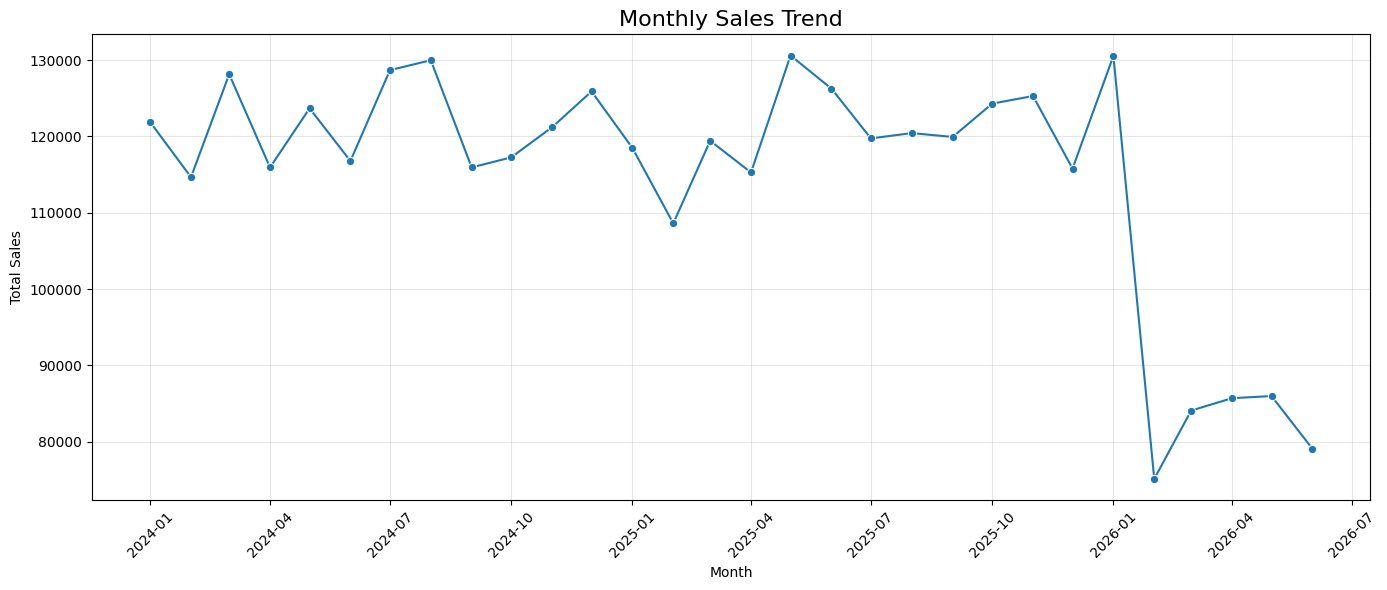

In [140]:

# Step 5.3: Monthly Sales Analysis

# Create a month column
eda_df["OrderMonth"] = eda_df["OrderDate"].dt.to_period("M")

# Aggregate sales by month
monthly_sales = (
    eda_df.groupby("OrderMonth")
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
)

# Convert month to timestamp for plotting
monthly_sales["OrderMonth"] = (
    monthly_sales["OrderMonth"].dt.to_timestamp()
)

print("MONTHLY SALES SUMMARY")
display(monthly_sales.round(2))

# Plot monthly sales
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_sales,
    x="OrderMonth",
    y="TotalSales",
    marker="o"
)

plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [141]:

# Step 5.4: Investigate the 2026 sales decline

monthly_check = (
    eda_df.groupby(eda_df["OrderDate"].dt.to_period("M"))
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        UnitsSold=("Quantity", "sum"),
        CompletedOrders=(
            "Status",
            lambda x: (x == "Completed").sum()
        )
    )
    .reset_index()
)

monthly_check["Month"] = monthly_check["OrderDate"].astype(str)

monthly_check["AverageSalesPerOrder"] = (
    monthly_check["TotalSales"] / monthly_check["TotalOrders"]
).round(2)

print("MONTHLY PERFORMANCE: JANUARY 2026 TO JUNE 2026")

display(
    monthly_check[
        monthly_check["OrderDate"] >= pd.Period("2026-01", freq="M")
    ][
        [
            "Month",
            "TotalSales",
            "TotalOrders",
            "UnitsSold",
            "CompletedOrders",
            "AverageSalesPerOrder"
        ]
    ].round(2)
)

print("\nMONTHLY ORDER COUNTS ACROSS ALL YEARS")

display(
    monthly_check[
        ["Month", "TotalSales", "TotalOrders", "AverageSalesPerOrder"]
    ].round(2)
)


MONTHLY PERFORMANCE: JANUARY 2026 TO JUNE 2026


,Month,TotalSales,TotalOrders,UnitsSold,CompletedOrders,AverageSalesPerOrder
24,2026-01,130550.0,1756,3395.0,1593,74.35
25,2026-02,75132.0,1074,1981.0,985,69.96
26,2026-03,84082.0,1224,2283.0,1109,68.69
27,2026-04,85706.0,1163,2207.0,1071,73.69
28,2026-05,85986.0,1237,2353.0,1142,69.51
29,2026-06,79085.0,1145,2097.0,1047,69.07



MONTHLY ORDER COUNTS ACROSS ALL YEARS


,Month,TotalSales,TotalOrders,AverageSalesPerOrder
0,2024-01,121893.0,1749,69.69
1,2024-02,114664.0,1592,72.03
2,2024-03,128150.0,1815,70.61
3,2024-04,115941.0,1676,69.18
4,2024-05,123683.0,1743,70.96
5,2024-06,116784.0,1690,69.10
6,2024-07,128689.0,1737,74.09
7,2024-08,129987.0,1813,71.70
8,2024-09,115943.0,1645,70.48
9,2024-10,117260.0,1730,67.78


In [142]:

# Step 5.5: Compare original and cleaned monthly order counts

# Keep one source record per OrderID for this comparison
source_orders = orders_raw.drop_duplicates(
    subset="OrderID"
).copy()

source_orders["OrderDate"] = pd.to_datetime(
    source_orders["OrderDate"], errors="coerce"
)

# Monthly order counts in the original source
source_monthly = (
    source_orders.dropna(subset=["OrderDate"])
    .groupby(source_orders["OrderDate"].dt.to_period("M"))
    .agg(OriginalOrders=("OrderID", "nunique"))
)

# Monthly order counts in the cleaned dataset
clean_monthly = (
    eda_df.groupby(eda_df["OrderDate"].dt.to_period("M"))
    .agg(CleanedOrders=("OrderID", "nunique"))
)

# Compare both datasets
monthly_comparison = source_monthly.join(
    clean_monthly, how="outer"
).fillna(0)

monthly_comparison["ExcludedOrders"] = (
    monthly_comparison["OriginalOrders"]
    - monthly_comparison["CleanedOrders"]
)

print("MONTHLY SOURCE VS CLEANED ORDER COUNTS")

display(
    monthly_comparison.loc["2024-01":"2026-06"]
    .round(0)
)

print("\n2026 MONTHLY COMPARISON")
display(
    monthly_comparison.loc["2026-01":"2026-06"]
    .round(0)
)


MONTHLY SOURCE VS CLEANED ORDER COUNTS


,OriginalOrders,CleanedOrders,ExcludedOrders
OrderDate,,,
2024-01,1771,1749,22
2024-02,1611,1592,19
2024-03,1839,1815,24
2024-04,1700,1676,24
2024-05,1770,1743,27
2024-06,1717,1690,27
2024-07,1761,1737,24
2024-08,1843,1813,30
2024-09,1663,1645,18



2026 MONTHLY COMPARISON


,OriginalOrders,CleanedOrders,ExcludedOrders
OrderDate,,,
2026-01,1776,1756,20
2026-02,1088,1074,14
2026-03,1241,1224,17
2026-04,1182,1163,19
2026-05,1257,1237,20
2026-06,1161,1145,16


JANUARY–JUNE: ORDER COUNTS


Year,2024,2025,2026
MonthNumber,,,
January,1749,1754,1756
February,1592,1557,1074
March,1815,1804,1224
April,1676,1734,1163
May,1743,1766,1237
June,1690,1802,1145



JANUARY–JUNE: RECORDED SALES


Year,2024,2025,2026
MonthNumber,,,
January,121893.0,118487.0,130550.0
February,114664.0,108609.0,75132.0
March,128150.0,119432.0,84082.0
April,115941.0,115278.0,85706.0
May,123683.0,130607.0,85986.0
June,116784.0,126269.0,79085.0


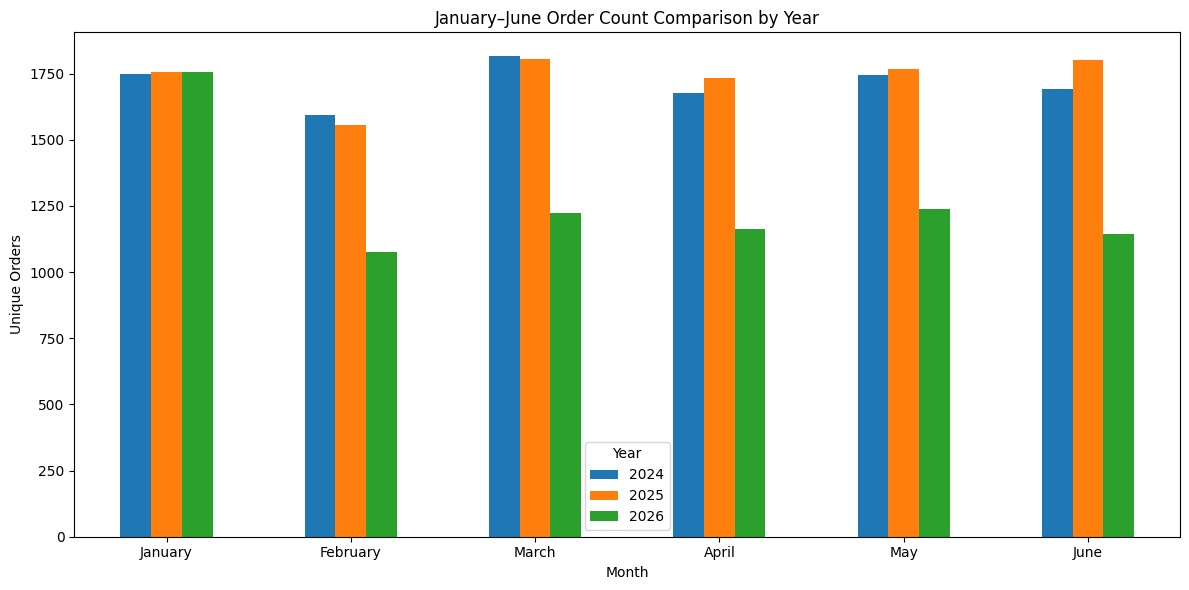

In [143]:

# Step 5.6: Compare monthly order counts across years

comparison_df = eda_df.copy()

comparison_df["Year"] = comparison_df["OrderDate"].dt.year
comparison_df["MonthNumber"] = comparison_df["OrderDate"].dt.month

monthly_year_comparison = (
    comparison_df.groupby(["Year", "MonthNumber"])
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique")
    )
    .reset_index()
)

# Compare January to June only
jan_jun = monthly_year_comparison[
    monthly_year_comparison["MonthNumber"].between(1, 6)
]

orders_pivot = jan_jun.pivot(
    index="MonthNumber",
    columns="Year",
    values="TotalOrders"
)

sales_pivot = jan_jun.pivot(
    index="MonthNumber",
    columns="Year",
    values="TotalSales"
)

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June"
}

orders_pivot.index = orders_pivot.index.map(month_names)
sales_pivot.index = sales_pivot.index.map(month_names)

print("JANUARY–JUNE: ORDER COUNTS")
display(orders_pivot)

print("\nJANUARY–JUNE: RECORDED SALES")
display(sales_pivot.round(2))

# Plot order counts
orders_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("January–June Order Count Comparison by Year")
plt.xlabel("Month")
plt.ylabel("Unique Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Category,TotalSales,TotalOrders,UnitsSold,AverageSales,SalesSharePercent
1,Electronics,1751037.0,17765,33030.0,98.57,50.83
0,Accessories,553023.0,18189,34524.0,30.40,16.05
3,Home Office,446065.0,3122,5920.0,142.88,12.95
5,Wearables,429450.0,3043,5675.0,141.13,12.47
2,Gaming,198037.0,1663,3152.0,119.08,5.75
4,Stationery,67218.0,5440,10331.0,12.36,1.95


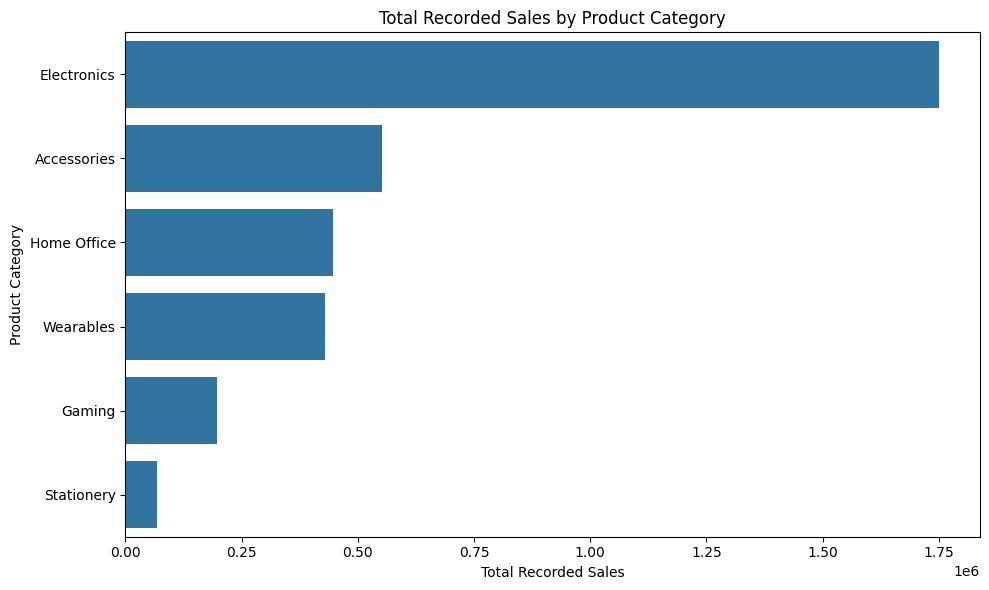

In [144]:

# Step 5.7: Product Category Performance

category_performance = (
    eda_df.groupby("Category")
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        UnitsSold=("Quantity", "sum"),
        AverageSales=("Sales", "mean")
    )
    .reset_index()
)

category_performance["SalesSharePercent"] = (
    category_performance["TotalSales"]
    / category_performance["TotalSales"].sum()
    * 100
).round(2)

category_performance = category_performance.sort_values(
    "TotalSales", ascending=False
)

display(category_performance.round(2))

# Visualise recorded sales by category
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(
    data=category_performance,
    x="TotalSales",
    y="Category"
)
plt.title("Total Recorded Sales by Product Category")
plt.xlabel("Total Recorded Sales")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


,ProductID,ProductName,Category,TotalSales,TotalOrders,UnitsSold
6,2007,Headphones,Electronics,333411.0,2559,4802.0
11,2012,Office Chair,Home Office,329292.0,1033,1977.0
18,2019,Tablet,Electronics,292344.0,658,1228.0
8,2009,Smart Watch,Wearables,259590.0,1251,2344.0
17,2018,Microphone,Electronics,230139.0,1539,2929.0
1,2002,Mechanical Keyboard,Electronics,229676.0,2153,3995.0
14,2015,Bluetooth Speaker,Electronics,213311.0,2132,3981.0
19,2020,Gaming Controller,Gaming,198037.0,1663,3152.0
3,2004,Power Bank,Electronics,180004.0,2970,5560.0
9,2010,Fitness Band,Wearables,169860.0,1792,3331.0


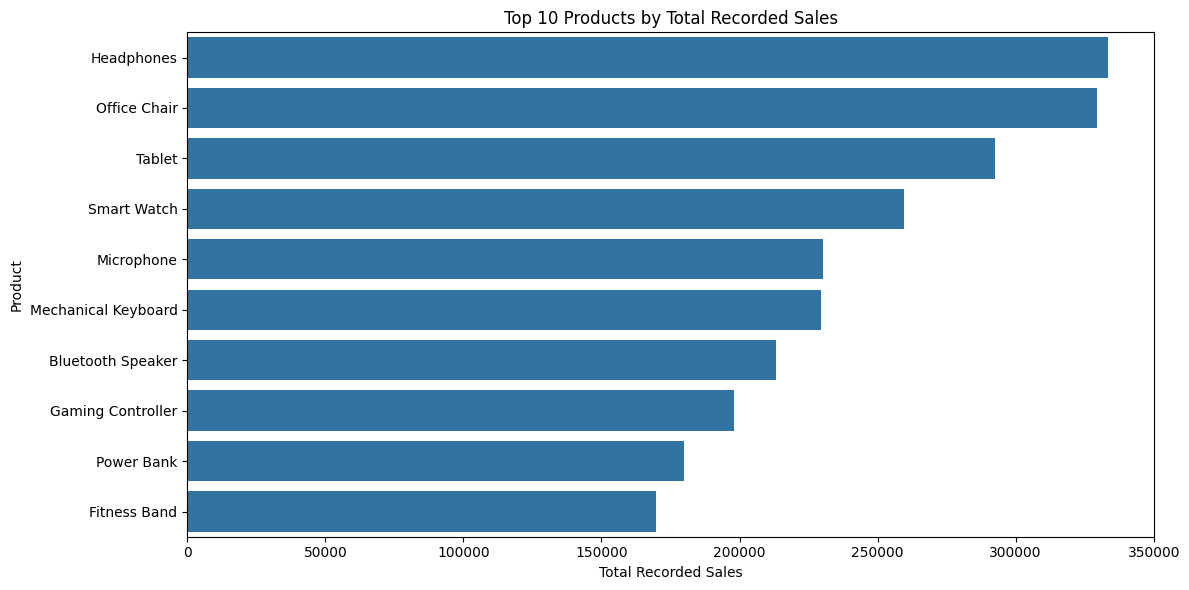

In [145]:

# Step 5.8: Top 10 Products by Recorded Sales

product_performance = (
    eda_df.groupby(["ProductID", "ProductName", "Category"])
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
)

product_performance = product_performance.sort_values(
    "TotalSales", ascending=False
)

top_10_products = product_performance.head(10)

display(top_10_products.round(2))

# Visualise the top 10 products
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_10_products,
    x="TotalSales",
    y="ProductName"
)
plt.title("Top 10 Products by Total Recorded Sales")
plt.xlabel("Total Recorded Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [146]:

# Step 5.9: Product Sales Efficiency

product_efficiency = product_performance.copy()

product_efficiency["SalesPerOrder"] = (
    product_efficiency["TotalSales"]
    / product_efficiency["TotalOrders"].replace(0, float("nan"))
).round(2)

product_efficiency["SalesPerUnit"] = (
    product_efficiency["TotalSales"]
    / product_efficiency["UnitsSold"].replace(0, float("nan"))
).round(2)

top_10_efficiency = (
    product_efficiency
    .sort_values("TotalSales", ascending=False)
    .head(10)
)

display(
    top_10_efficiency[
        [
            "ProductName",
            "Category",
            "TotalSales",
            "TotalOrders",
            "UnitsSold",
            "SalesPerOrder",
            "SalesPerUnit"
        ]
    ].round(2)
)


,ProductName,Category,TotalSales,TotalOrders,UnitsSold,SalesPerOrder,SalesPerUnit
6,Headphones,Electronics,333411.0,2559,4802.0,130.29,69.43
11,Office Chair,Home Office,329292.0,1033,1977.0,318.77,166.56
18,Tablet,Electronics,292344.0,658,1228.0,444.29,238.07
8,Smart Watch,Wearables,259590.0,1251,2344.0,207.51,110.75
17,Microphone,Electronics,230139.0,1539,2929.0,149.54,78.57
1,Mechanical Keyboard,Electronics,229676.0,2153,3995.0,106.68,57.49
14,Bluetooth Speaker,Electronics,213311.0,2132,3981.0,100.05,53.58
19,Gaming Controller,Gaming,198037.0,1663,3152.0,119.08,62.83
3,Power Bank,Electronics,180004.0,2970,5560.0,60.61,32.37
9,Fitness Band,Wearables,169860.0,1792,3331.0,94.79,50.99


,PaymentMethod,TotalSales,TotalOrders,UnitsSold,AverageSales,SalesSharePercent
2,Gateway,1667053.0,23894,44767.0,69.77,48.39
0,CardToCard,830572.0,11744,22287.0,70.72,24.11
3,Wallet,604131.0,8661,16294.0,69.75,17.54
1,Cash,343074.0,4923,9284.0,69.69,9.96


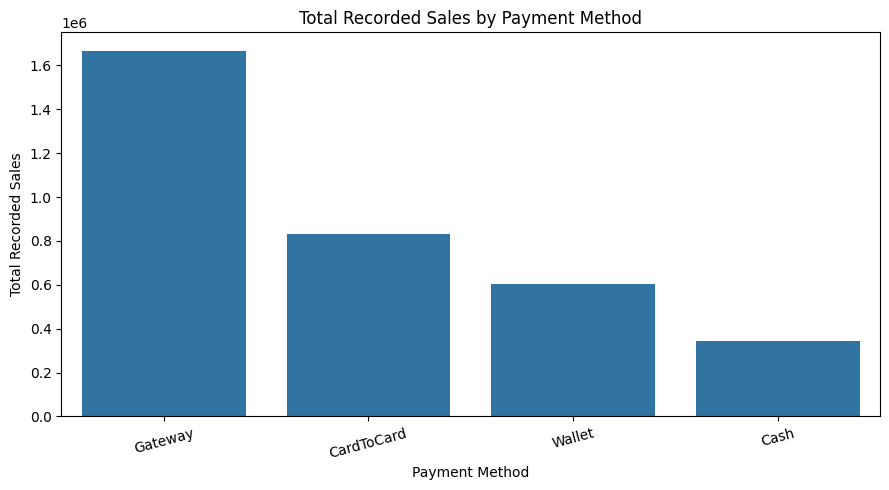

In [147]:

# Step 5.10: Sales by Payment Method

payment_analysis = (
    eda_df.groupby("PaymentMethod")
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        UnitsSold=("Quantity", "sum"),
        AverageSales=("Sales", "mean")
    )
    .reset_index()
)

payment_analysis["SalesSharePercent"] = (
    payment_analysis["TotalSales"]
    / payment_analysis["TotalSales"].sum()
    * 100
).round(2)

payment_analysis = payment_analysis.sort_values(
    "TotalSales", ascending=False
)

display(payment_analysis.round(2))

# Visualise recorded sales by payment method
plt.figure(figsize=(9, 5))
sns.barplot(
    data=payment_analysis,
    x="PaymentMethod",
    y="TotalSales"
)
plt.title("Total Recorded Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Recorded Sales")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


,Status,TotalSales,TotalOrders,UnitsSold,OrderSharePercent,SalesSharePercent
1,Completed,3162844.0,45276,85170.0,91.98,91.81
0,Cancelled,180171.0,2438,4634.0,4.95,5.23
2,Returned,101815.0,1508,2828.0,3.06,2.96


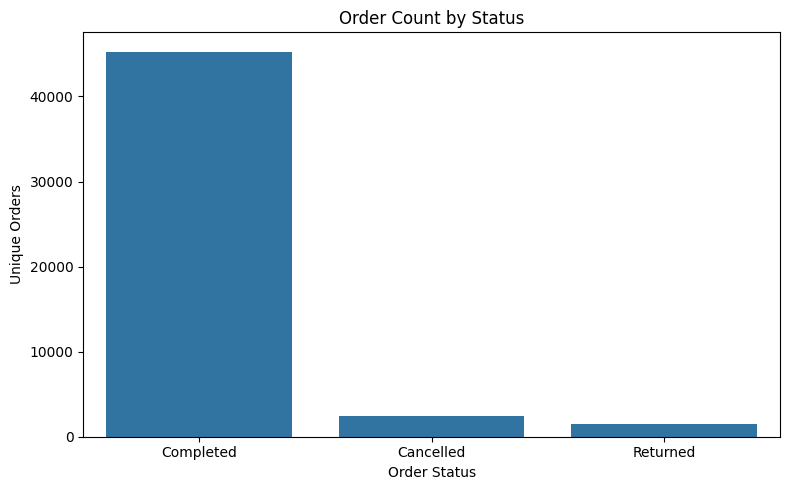

In [148]:

# Step 5.11: Order Status Analysis


status_analysis = (
    eda_df.groupby("Status")
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
)

status_analysis["OrderSharePercent"] = (
    status_analysis["TotalOrders"]
    / status_analysis["TotalOrders"].sum()
    * 100
).round(2)

status_analysis["SalesSharePercent"] = (
    status_analysis["TotalSales"]
    / status_analysis["TotalSales"].sum()
    * 100
).round(2)

status_analysis = status_analysis.sort_values(
    "TotalOrders", ascending=False
)

display(status_analysis.round(2))

# Visualise the number of orders by status
plt.figure(figsize=(8, 5))
sns.barplot(
    data=status_analysis,
    x="Status",
    y="TotalOrders"
)
plt.title("Order Count by Status")
plt.xlabel("Order Status")
plt.ylabel("Unique Orders")
plt.tight_layout()
plt.show()



ORDER COUNTS BY PAYMENT METHOD


Status,Cancelled,Completed,Returned,TotalOrders
PaymentMethod,,,,
CardToCard,601,10813,330,11744
Cash,240,4532,151,4923
Gateway,1156,21973,765,23894
Wallet,441,7958,262,8661


ORDER STATUS PERCENTAGES WITHIN EACH PAYMENT METHOD


Status,Cancelled,Completed,Returned
PaymentMethod,,,
CardToCard,5.12,92.07,2.81
Cash,4.88,92.06,3.07
Gateway,4.84,91.96,3.20
Wallet,5.09,91.88,3.03


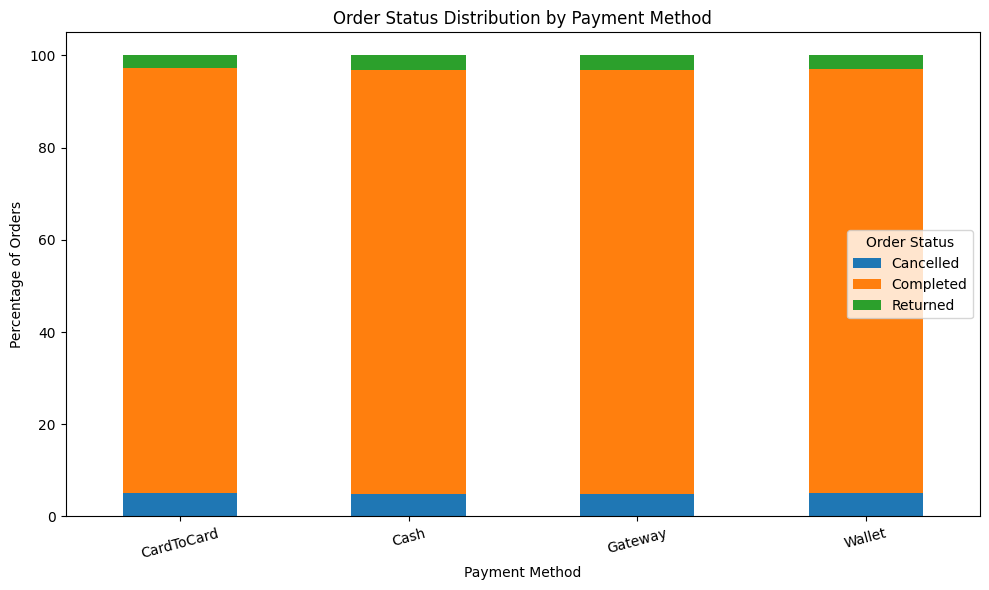

In [149]:

# Step 5.12: Order Status by Payment Method

status_payment = pd.crosstab(
    eda_df["PaymentMethod"],
    eda_df["Status"]
)

status_payment["TotalOrders"] = status_payment.sum(axis=1)

status_payment_percent = (
    pd.crosstab(
        eda_df["PaymentMethod"],
        eda_df["Status"],
        normalize="index"
    ) * 100
).round(2)

print("ORDER COUNTS BY PAYMENT METHOD")
display(status_payment)

print("ORDER STATUS PERCENTAGES WITHIN EACH PAYMENT METHOD")
display(status_payment_percent)

# Visualise the status distribution
status_payment_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Order Status Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Orders")
plt.xticks(rotation=15)
plt.legend(title="Order Status")
plt.tight_layout()
plt.show()


,CustomerSegment,TotalSales,TotalOrders,UnitsSold,AverageSalesPerRow,SalesSharePercent
1,Regular,1914854.0,27296,51279.0,70.15,55.59
0,New,1196104.0,17056,32293.0,70.13,34.72
2,VIP,333872.0,4870,9060.0,68.56,9.69


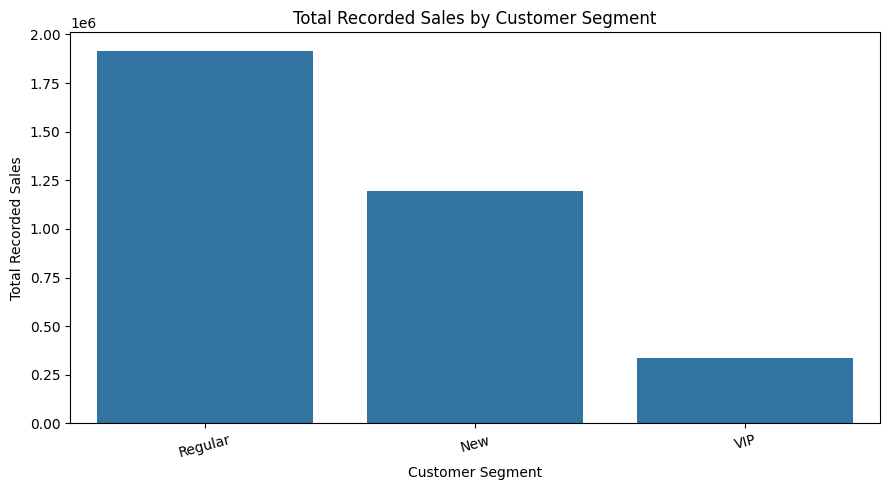

In [150]:

# Step 5.13: Customer Segment Analysis

segment_analysis = (
    eda_df.groupby("CustomerSegment")
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        UnitsSold=("Quantity", "sum"),
        AverageSalesPerRow=("Sales", "mean")
    )
    .reset_index()
)

segment_analysis["SalesSharePercent"] = (
    segment_analysis["TotalSales"]
    / segment_analysis["TotalSales"].sum()
    * 100
).round(2)

segment_analysis = segment_analysis.sort_values(
    "TotalSales", ascending=False
)

display(segment_analysis.round(2))

# Visualise recorded sales by customer segment
plt.figure(figsize=(9, 5))
sns.barplot(
    data=segment_analysis,
    x="CustomerSegment",
    y="TotalSales"
)
plt.title("Total Recorded Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Recorded Sales")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [151]:

# Step 5.14: Customer-Level Performance

customer_analysis = (
    eda_df.groupby("CustomerID")
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        UnitsSold=("Quantity", "sum"),
        CustomerSegment=("CustomerSegment", "first"),
        City=("City", "first")
    )
    .reset_index()
)

customer_analysis = customer_analysis.sort_values(
    "TotalSales", ascending=False
)

print("TOP 10 CUSTOMERS BY RECORDED SALES")
display(customer_analysis.head(10).round(2))

print("\nCUSTOMER-LEVEL SUMMARY")
display(
    customer_analysis[
        ["TotalSales", "TotalOrders", "UnitsSold"]
    ].describe().round(2)
)


TOP 10 CUSTOMERS BY RECORDED SALES


,CustomerID,TotalSales,TotalOrders,UnitsSold,CustomerSegment,City
345,100353,2467.0,7,20.0,New,Tabriz
8935,109093,2090.0,8,15.0,New,Rasht
4836,104916,2089.0,8,21.0,Regular,Mashhad
1777,101806,2079.0,7,16.0,Regular,Karaj
3085,103135,2056.0,7,18.0,Regular,Tehran
6696,106809,2033.0,10,19.0,Regular,Tehran
8342,108485,1974.0,8,28.0,New,Mashhad
3096,103146,1838.0,12,25.0,New,Shiraz
9561,109735,1837.0,8,19.0,New,Tabriz
8906,109061,1796.0,9,23.0,Regular,Tehran



CUSTOMER-LEVEL SUMMARY


,TotalSales,TotalOrders,UnitsSold
count,9820.00,9820.00,9820.00
mean,350.80,5.01,9.43
std,262.23,2.19,4.78
min,6.00,1.00,1.00
25%,166.00,3.00,6.00
50%,290.00,5.00,9.00
75%,465.00,6.00,12.00
max,2467.00,15.00,35.00


In [152]:

# Step 5.15: Customer Sales Concentration

customer_ranked = customer_analysis.sort_values(
    "TotalSales", ascending=False
).reset_index(drop=True)

total_customer_sales = customer_ranked["TotalSales"].sum()
customer_count = len(customer_ranked)

top_10_count = round(customer_count * 0.10)
top_20_count = round(customer_count * 0.20)

top_10_sales = customer_ranked.head(top_10_count)["TotalSales"].sum()
top_20_sales = customer_ranked.head(top_20_count)["TotalSales"].sum()

concentration_summary = pd.DataFrame({
    "Metric": [
        "Total unique customers",
        "Total recorded customer sales",
        "Top 10% of customers",
        "Top 10% sales contribution (%)",
        "Top 20% of customers",
        "Top 20% sales contribution (%)"
    ],
    "Value": [
        customer_count,
        round(total_customer_sales, 2),
        top_10_count,
        round(top_10_sales / total_customer_sales * 100, 2),
        top_20_count,
        round(top_20_sales / total_customer_sales * 100, 2)
    ]
})

display(concentration_summary)


,Metric,Value
0,Total unique customers,9820.00
1,Total recorded customer sales,3444830.00
2,Top 10% of customers,982.00
3,Top 10% sales contribution (%),26.62
4,Top 20% of customers,1964.00
5,Top 20% sales contribution (%),43.57


In [153]:

# Step 5.16: Customer Attribute Consistency Check

customer_consistency = (
    eda_df.groupby("CustomerID")
    .agg(
        SegmentCount=("CustomerSegment", "nunique"),
        CityCount=("City", "nunique"),
        SegmentValues=("CustomerSegment", "nunique")
    )
)

inconsistent_segments = customer_consistency[
    customer_consistency["SegmentCount"] > 1
]

inconsistent_cities = customer_consistency[
    customer_consistency["CityCount"] > 1
]

print("Customers with multiple segments:",
      len(inconsistent_segments))

print("Customers with multiple cities:",
      len(inconsistent_cities))


Customers with multiple segments: 0
Customers with multiple cities: 0


,City,TotalSales,TotalOrders,UnitsSold,UniqueCustomers,SalesSharePercent
9,Tehran,963907.0,14001,26135.0,2784,27.98
4,Mashhad,438112.0,6222,11720.0,1278,12.72
2,Karaj,350173.0,4966,9351.0,1008,10.17
1,Isfahan,334531.0,4916,9203.0,949,9.71
7,Shiraz,310775.0,4363,8258.0,861,9.02
8,Tabriz,292074.0,4134,7811.0,840,8.48
0,Ahvaz,211055.0,2923,5531.0,584,6.13
6,Rasht,205882.0,2857,5422.0,558,5.98
3,Kerman,175171.0,2465,4726.0,477,5.09
5,Qom,163150.0,2375,4475.0,481,4.74


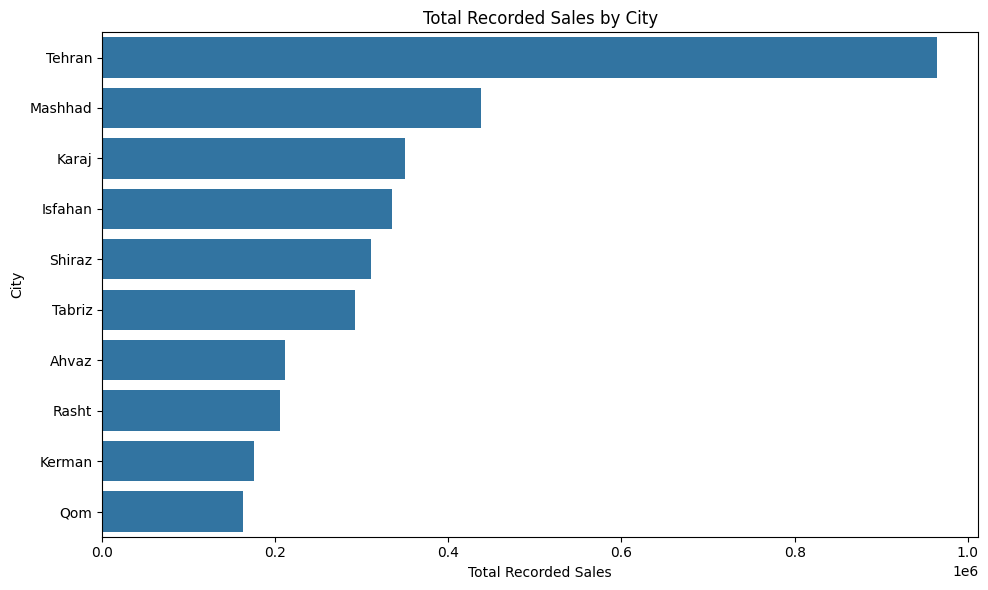

In [154]:

# Step 5.17: City-Level Sales Analysis

city_analysis = (
    eda_df.groupby("City")
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        UnitsSold=("Quantity", "sum"),
        UniqueCustomers=("CustomerID", "nunique")
    )
    .reset_index()
)

city_analysis["SalesSharePercent"] = (
    city_analysis["TotalSales"]
    / city_analysis["TotalSales"].sum()
    * 100
).round(2)

city_analysis = city_analysis.sort_values(
    "TotalSales", ascending=False
)

display(city_analysis.round(2))

# Plot recorded sales by city
plt.figure(figsize=(10, 6))
sns.barplot(
    data=city_analysis,
    x="TotalSales",
    y="City"
)
plt.title("Total Recorded Sales by City")
plt.xlabel("Total Recorded Sales")
plt.ylabel("City")
plt.tight_layout()
plt.show()


,City,TotalSales,UniqueCustomers,SalesPerCustomer,SalesSharePercent
6,Rasht,205882.0,558,368.96,5.98
3,Kerman,175171.0,477,367.23,5.09
0,Ahvaz,211055.0,584,361.40,6.13
7,Shiraz,310775.0,861,360.95,9.02
1,Isfahan,334531.0,949,352.51,9.71
8,Tabriz,292074.0,840,347.71,8.48
2,Karaj,350173.0,1008,347.39,10.17
9,Tehran,963907.0,2784,346.23,27.98
4,Mashhad,438112.0,1278,342.81,12.72
5,Qom,163150.0,481,339.19,4.74


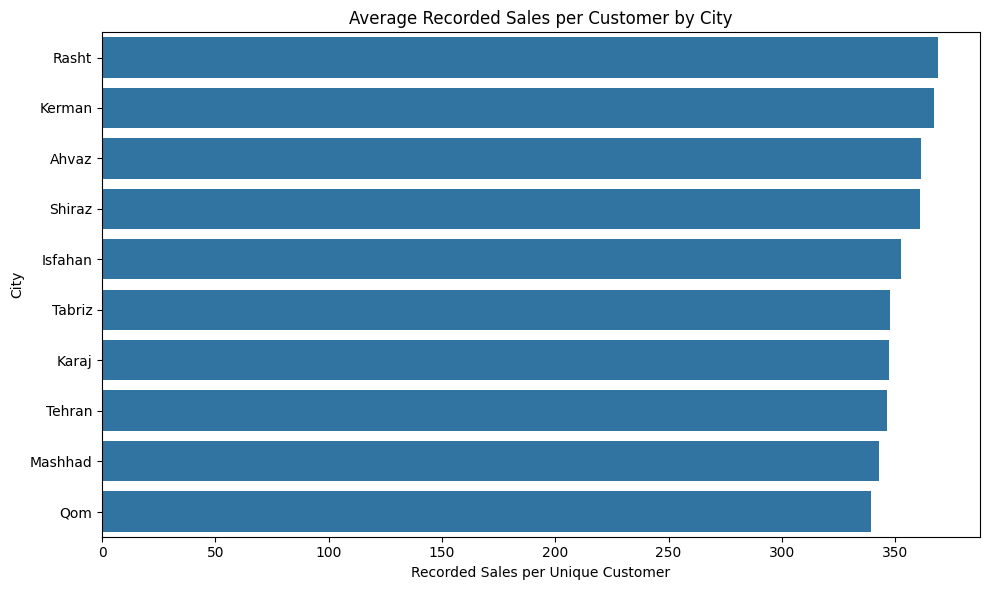

In [155]:

# Step 5.18: Average Recorded Sales per Customer by City

city_analysis["SalesPerCustomer"] = (
    city_analysis["TotalSales"]
    / city_analysis["UniqueCustomers"]
).round(2)

city_customer_comparison = city_analysis[
    [
        "City",
        "TotalSales",
        "UniqueCustomers",
        "SalesPerCustomer",
        "SalesSharePercent"
    ]
].sort_values("SalesPerCustomer", ascending=False)

display(city_customer_comparison.round(2))

# Visualise sales per customer
plt.figure(figsize=(10, 6))
sns.barplot(
    data=city_customer_comparison,
    x="SalesPerCustomer",
    y="City"
)
plt.title("Average Recorded Sales per Customer by City")
plt.xlabel("Recorded Sales per Unique Customer")
plt.ylabel("City")
plt.tight_layout()
plt.show()


,Discount,TotalSales,TotalOrders,UnitsSold,AverageSales,SalesSharePercent
0,0.0,1297097.0,17350,32478.0,74.76,37.65
1,5.0,768308.0,10692,20284.0,71.86,22.30
2,10.0,674145.0,9827,18527.0,68.60,19.57
3,15.0,382206.0,5911,11121.0,64.66,11.10
4,20.0,215968.0,3520,6600.0,61.35,6.27
5,30.0,107106.0,1922,3622.0,55.73,3.11


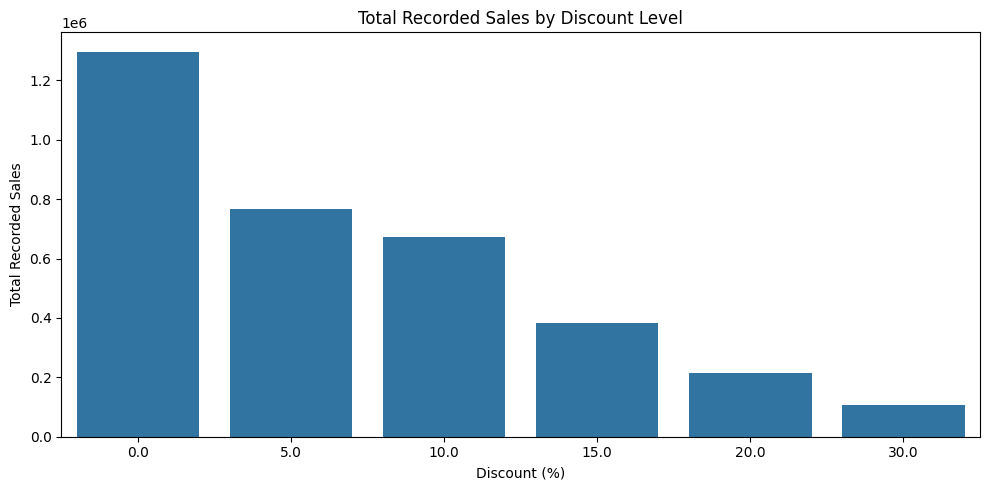

In [156]:

# Step 5.19: Discount Analysis

discount_analysis = (
    eda_df.groupby("Discount")
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        UnitsSold=("Quantity", "sum"),
        AverageSales=("Sales", "mean")
    )
    .reset_index()
    .sort_values("Discount")
)

discount_analysis["SalesSharePercent"] = (
    discount_analysis["TotalSales"]
    / discount_analysis["TotalSales"].sum()
    * 100
).round(2)

display(discount_analysis.round(2))

# Visualise recorded sales by discount level
plt.figure(figsize=(10, 5))
sns.barplot(
    data=discount_analysis,
    x="Discount",
    y="TotalSales"
)
plt.title("Total Recorded Sales by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Total Recorded Sales")
plt.tight_layout()
plt.show()


,Category,Discount,TotalSales,TotalOrders,AverageSales,SalesShareWithinCategory
0,Accessories,0.0,206554.0,6360,32.48,37.35
1,Accessories,5.0,125471.0,3973,31.58,22.69
2,Accessories,10.0,107692.0,3639,29.59,19.47
3,Accessories,15.0,64368.0,2230,28.86,11.64
4,Accessories,20.0,32169.0,1282,25.09,5.82
5,Accessories,30.0,16769.0,705,23.79,3.03
6,Electronics,0.0,650790.0,6237,104.34,37.17
7,Electronics,5.0,398952.0,3900,102.30,22.78
8,Electronics,10.0,342684.0,3558,96.31,19.57
9,Electronics,15.0,193555.0,2082,92.97,11.05


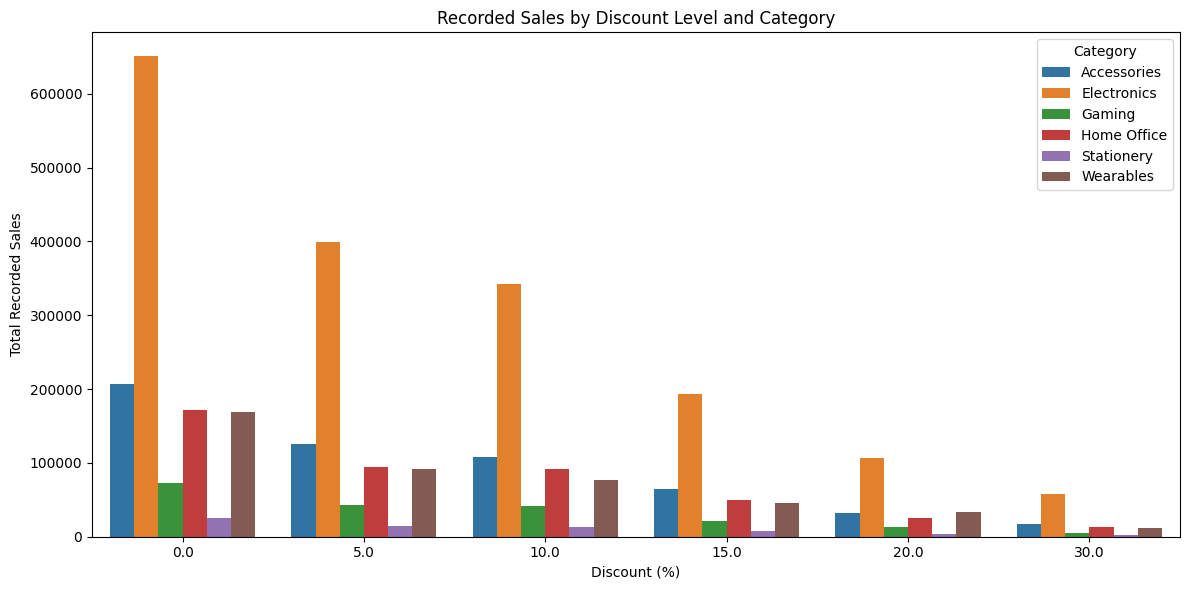

In [157]:

# Step 5.20: Discount Analysis by Category

category_discount = (
    eda_df.groupby(["Category", "Discount"])
    .agg(
        TotalSales=("Sales", "sum"),
        TotalOrders=("OrderID", "nunique"),
        AverageSales=("Sales", "mean")
    )
    .reset_index()
)

category_discount["SalesShareWithinCategory"] = (
    category_discount["TotalSales"]
    / category_discount.groupby("Category")["TotalSales"].transform("sum")
    * 100
).round(2)

display(
    category_discount.sort_values(
        ["Category", "Discount"]
    ).round(2)
)

# Visualise recorded sales by discount within each category
plt.figure(figsize=(12, 6))
sns.barplot(
    data=category_discount,
    x="Discount",
    y="TotalSales",
    hue="Category"
)
plt.title("Recorded Sales by Discount Level and Category")
plt.xlabel("Discount (%)")
plt.ylabel("Total Recorded Sales")
plt.tight_layout()
plt.show()


In [158]:

# Step 5.21: Validate the Recorded Sales Formula

sales_check = eda_df.copy()

sales_check["ExpectedSales"] = (
    sales_check["Quantity"]
    * sales_check["UnitPrice"]
    * (1 - sales_check["Discount"] / 100)
)

sales_check["SalesDifference"] = (
    sales_check["Sales"] - sales_check["ExpectedSales"]
)

sales_check["AbsoluteDifference"] = (
    sales_check["SalesDifference"].abs()
)

tolerance = 0.01

matching_rows = (
    sales_check["AbsoluteDifference"] <= tolerance
).sum()

mismatching_rows = (
    sales_check["AbsoluteDifference"] > tolerance
).sum()

sales_validation = pd.DataFrame({
    "Metric": [
        "Total rows checked",
        "Rows matching expected formula",
        "Rows not matching expected formula",
        "Percentage matching",
        "Mean absolute difference",
        "Maximum absolute difference"
    ],
    "Value": [
        len(sales_check),
        matching_rows,
        mismatching_rows,
        round(matching_rows / len(sales_check) * 100, 2),
        round(sales_check["AbsoluteDifference"].mean(), 2),
        round(sales_check["AbsoluteDifference"].max(), 2)
    ]
})

display(sales_validation)

# Inspect a few mismatching rows
display(
    sales_check.loc[
        sales_check["AbsoluteDifference"] > tolerance,
        [
            "ProductName",
            "Quantity",
            "UnitPrice",
            "Discount",
            "Sales",
            "ExpectedSales",
            "SalesDifference"
        ]
    ].head(10).round(2)
)


,Metric,Value
0,Total rows checked,49222.00
1,Rows matching expected formula,21210.00
2,Rows not matching expected formula,28012.00
3,Percentage matching,43.09
4,Mean absolute difference,0.16
5,Maximum absolute difference,0.50


,ProductName,Quantity,UnitPrice,Discount,Sales,ExpectedSales,SalesDifference
0,USB-C Cable,4.0,9.0,10.0,32.0,32.40,-0.40
1,Backpack,1.0,42.0,10.0,38.0,37.80,0.20
2,Mechanical Keyboard,1.0,62.0,20.0,50.0,49.60,0.40
6,HDMI Cable,1.0,11.0,5.0,10.0,10.45,-0.45
8,Power Bank,1.0,35.0,10.0,32.0,31.50,0.50
9,Backpack,2.0,42.0,5.0,80.0,79.80,0.20
10,Power Bank,3.0,35.0,30.0,74.0,73.50,0.50
11,Wireless Mouse,1.0,18.0,5.0,17.0,17.10,-0.10
12,Laptop Stand,3.0,28.0,10.0,76.0,75.60,0.40
13,Wireless Mouse,2.0,18.0,5.0,34.0,34.20,-0.20


In [159]:

# Step 5.22: Test an Alternative Sales Formula

sales_check["RoundedUnitPriceSales"] = (
    (
        sales_check["UnitPrice"]
        * (1 - sales_check["Discount"] / 100)
    ).round(0)
    * sales_check["Quantity"]
)

sales_check["RoundedFormulaDifference"] = (
    sales_check["Sales"]
    - sales_check["RoundedUnitPriceSales"]
)

rounded_matches = (
    sales_check["RoundedFormulaDifference"].abs() <= 0.01
).sum()

rounded_mismatches = len(sales_check) - rounded_matches

formula_comparison = pd.DataFrame({
    "Formula": [
        "Quantity × Unit Price × (1 − Discount)",
        "Quantity × rounded discounted unit price"
    ],
    "MatchingRows": [
        matching_rows,
        rounded_matches
    ],
    "MismatchingRows": [
        mismatching_rows,
        rounded_mismatches
    ],
    "MatchPercentage": [
        round(matching_rows / len(sales_check) * 100, 2),
        round(rounded_matches / len(sales_check) * 100, 2)
    ]
})

display(formula_comparison)

print("Sample rows still mismatching under the alternative formula:")
display(
    sales_check.loc[
        sales_check["RoundedFormulaDifference"].abs() > 0.01,
        [
            "ProductName",
            "Quantity",
            "UnitPrice",
            "Discount",
            "Sales",
            "RoundedUnitPriceSales",
            "RoundedFormulaDifference"
        ]
    ].head(10).round(2)
)


,Formula,MatchingRows,MismatchingRows,MatchPercentage
0,Quantity × Unit Price × (1 − Discount),21210,28012,43.09
1,Quantity × rounded discounted unit price,39338,9884,79.92


Sample rows still mismatching under the alternative formula:


,ProductName,Quantity,UnitPrice,Discount,Sales,RoundedUnitPriceSales,RoundedFormulaDifference
10,Power Bank,3.0,35.0,30.0,74.0,72.0,2.0
12,Laptop Stand,3.0,28.0,10.0,76.0,75.0,1.0
32,Headphones,3.0,75.0,5.0,214.0,213.0,1.0
34,Phone Case,5.0,14.0,10.0,63.0,65.0,-2.0
36,Wireless Mouse,4.0,18.0,15.0,61.0,60.0,1.0
37,Notebook,5.0,7.0,5.0,33.0,35.0,-2.0
38,Desk Lamp,4.0,32.0,10.0,115.0,116.0,-1.0
39,Fitness Band,2.0,55.0,30.0,77.0,76.0,1.0
43,HDMI Cable,2.0,11.0,5.0,21.0,20.0,1.0
50,Notebook,3.0,7.0,10.0,19.0,18.0,1.0


In [160]:

# Step 5.23: Formula Mismatch Analysis by Discount

sales_check["AlternativeFormulaMatches"] = (
    sales_check["RoundedFormulaDifference"].abs() <= 0.01
)

discount_validation = (
    sales_check.groupby("Discount")
    .agg(
        TotalRows=("Sales", "size"),
        MatchingRows=("AlternativeFormulaMatches", "sum")
    )
    .reset_index()
)

discount_validation["MismatchingRows"] = (
    discount_validation["TotalRows"]
    - discount_validation["MatchingRows"]
)

discount_validation["MatchPercentage"] = (
    discount_validation["MatchingRows"]
    / discount_validation["TotalRows"]
    * 100
).round(2)

display(discount_validation)


,Discount,TotalRows,MatchingRows,MismatchingRows,MatchPercentage
0,0.0,17350,17350,0,100.00
1,5.0,10692,7086,3606,66.27
2,10.0,9827,6996,2831,71.19
3,15.0,5911,4338,1573,73.39
4,20.0,3520,2424,1096,68.86
5,30.0,1922,1144,778,59.52


In [161]:

# Step 5.24: Final Dataset Validation

final_validation = pd.DataFrame({
    "Metric": [
        "Total rows",
        "Unique order IDs",
        "Unique customers",
        "Missing values across columns",
        "Exact duplicate rows",
        "Invalid OrderDate values",
        "Negative quantities",
        "Negative recorded sales",
        "Earliest order date",
        "Latest order date"
    ],
    "Value": [
        len(eda_df),
        eda_df["OrderID"].nunique(),
        eda_df["CustomerID"].nunique(),
        int(eda_df.isna().sum().sum()),
        int(eda_df.duplicated().sum()),
        int(eda_df["OrderDate"].isna().sum()),
        int((eda_df["Quantity"] < 0).sum()),
        int((eda_df["Sales"] < 0).sum()),
        str(eda_df["OrderDate"].min().date()),
        str(eda_df["OrderDate"].max().date())
    ]
})

display(final_validation)


,Metric,Value
0,Total rows,49222
1,Unique order IDs,49222
2,Unique customers,9820
3,Missing values across columns,0
4,Exact duplicate rows,0
5,Invalid OrderDate values,0
6,Negative quantities,19
7,Negative recorded sales,19
8,Earliest order date,2024-01-01
9,Latest order date,2026-06-30


In [162]:

# Step 6.1: Inspect Project Files

import os

print("Current working directory:", os.getcwd())
print("\nFiles available in the notebook environment:")

for file in sorted(os.listdir(".")):
    print(file)


Current working directory: /content

Files available in the notebook environment:
.config
.ipynb_checkpoints
clean_final_data.csv
customers.csv
ecommerce-sales-analysis
ecommerce_project_data.zip
ecommerce_sales_eda (1).ipynb
orders.csv
payments.csv
products.csv
sample_data


In [163]:

import os

# Create the project folder structure
project_folder = "/content/ecommerce-sales-analysis"

folders = [
    "data",
    "notebooks",
    "images"
]

for folder in folders:
    os.makedirs(
        os.path.join(project_folder, folder),
        exist_ok=True
    )

print("Project folders created successfully!")

for root, dirs, files in os.walk(project_folder):
    print(root.replace(project_folder, "ecommerce-sales-analysis"))


Project folders created successfully!
ecommerce-sales-analysis
ecommerce-sales-analysis/notebooks
ecommerce-sales-analysis/images
ecommerce-sales-analysis/data


In [164]:

import os

print("Files in /content:")
print(os.listdir("/content"))

print("\nSearching for your CSV files:")
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


Files in /content:
['.config', 'ecommerce_project_data.zip', 'payments.csv', '.ipynb_checkpoints', 'customers.csv', 'clean_final_data.csv', 'products.csv', 'ecommerce_sales_eda (1).ipynb', 'orders.csv', 'ecommerce-sales-analysis', 'sample_data']

Searching for your CSV files:
/content/payments.csv
/content/customers.csv
/content/clean_final_data.csv
/content/products.csv
/content/orders.csv
/content/ecommerce-sales-analysis/data/payments.csv
/content/ecommerce-sales-analysis/data/customers.csv
/content/ecommerce-sales-analysis/data/clean_final_data.csv
/content/ecommerce-sales-analysis/data/products.csv
/content/ecommerce-sales-analysis/data/orders.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv


In [165]:

import zipfile
import os

zip_path = "/content/ecommerce_project_data.zip"

with zipfile.ZipFile(zip_path, "r") as zip_file:
    print("Files inside ZIP:")
    print(zip_file.namelist())

    zip_file.extractall("/content")

print("\nRestored CSV files:")
for file in os.listdir("/content"):
    if file.endswith(".csv"):
        print(file)


Files inside ZIP:
[]

Restored CSV files:
payments.csv
customers.csv
clean_final_data.csv
products.csv
orders.csv


In [166]:
import pandas as pd

df = pd.read_csv("clean_final_data.csv")
print("Shape:", df.shape)
print(df.head())

Shape: (49222, 17)
   OrderID  CustomerID   OrderDate  ProductID  Quantity  Discount  \
0   500001      103695  2025-08-28       2003       4.0      10.0   
1   500002      107935  2024-05-31       2014       1.0      10.0   
2   500003      105141  2025-08-10       2002       1.0      20.0   
3   500004      108780  2024-10-11       2012       1.0      10.0   
4   500005      101187  2024-02-19       2008       2.0       0.0   

  PaymentMethod     Status   Age    City  SignupDate CustomerSegment  \
0       Gateway  Completed  36.0     Qom  2024-03-05         Regular   
1        Wallet  Completed  49.0  Kerman  2025-06-04         Regular   
2    CardToCard  Completed  36.0  Tehran  2025-10-19         Regular   
3       Gateway  Completed  45.0  Shiraz  2023-12-07         Regular   
4       Gateway  Completed  24.0   Karaj  2023-12-02         Regular   

           ProductName     Category  UnitPrice  Sales  OrderValue  
0          USB-C Cable  Accessories        9.0   32.0        32.0

In [167]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the restored dataset
df = pd.read_csv("clean_final_data.csv")

# Create the analysis copy
eda_df = df.copy()

# Convert date columns
eda_df["OrderDate"] = pd.to_datetime(
    eda_df["OrderDate"], errors="coerce"
)
eda_df["SignupDate"] = pd.to_datetime(
    eda_df["SignupDate"], errors="coerce"
)

print("Dataset restored successfully!")
print("Shape:", eda_df.shape)
print("Unique orders:", eda_df["OrderID"].nunique())
print("Unique customers:", eda_df["CustomerID"].nunique())


Dataset restored successfully!
Shape: (49222, 17)
Unique orders: 49222
Unique customers: 9820


In [168]:

import os
import shutil

project_folder = "/content/ecommerce-sales-analysis"

# Create project folders
for folder in ["data", "notebooks", "images"]:
    os.makedirs(
        os.path.join(project_folder, folder),
        exist_ok=True
    )

# Copy the restored dataset into the project
shutil.copy2(
    "/content/clean_final_data.csv",
    os.path.join(project_folder, "data", "clean_final_data.csv")
)

# Verify the copied dataset
data_path = os.path.join(
    project_folder, "data", "clean_final_data.csv"
)

check_df = pd.read_csv(data_path)

print("Project data prepared successfully!")
print("Dataset path:", data_path)
print("Dataset shape:", check_df.shape)
print("Project folders:", os.listdir(project_folder))


Project data prepared successfully!
Dataset path: /content/ecommerce-sales-analysis/data/clean_final_data.csv
Dataset shape: (49222, 17)
Project folders: ['notebooks', 'images', 'data']


In [169]:

import os

for filename in os.listdir("/content"):
    if filename.endswith(".ipynb"):
        print(filename)


ecommerce_sales_eda (1).ipynb


In [170]:
import shutil
import os

source = "/content/ecommerce_sales_eda (1).ipynb"
destination = "/content/ecommerce-sales-analysis/notebooks/ecommerce_sales_eda.ipynb"

shutil.copy2(source, destination)

print("Notebook copied successfully!")
print("Saved to:", destination)
print("File exists:", os.path.exists(destination))

Notebook copied successfully!
Saved to: /content/ecommerce-sales-analysis/notebooks/ecommerce_sales_eda.ipynb
File exists: True


In [171]:
import os

project_path = "/content/ecommerce-sales-analysis"

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for filename in files:
        file_path = os.path.join(root, filename)
        size_kb = os.path.getsize(file_path) / 1024
        print(f"{indent}    {filename} ({size_kb:.1f} KB)")

ecommerce-sales-analysis/
    notebooks/
        ecommerce_sales_eda.ipynb (1160.1 KB)
    images/
    data/
        payments.csv (1474.2 KB)
        customers.csv (351.0 KB)
        clean_final_data.csv (6023.1 KB)
        products.csv (0.7 KB)
        orders.csv (2763.6 KB)


In [172]:
import json

notebook_path = (
    "/content/ecommerce-sales-analysis/"
    "notebooks/ecommerce_sales_eda.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        if "read_csv" in source or "clean_final_data.csv" in source:
            print(f"\n--- Cell {i} ---")
            print(source[:1500])


--- Cell 0 ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/clean_final_data.csv")

print(df.shape)
display(df.head())

--- Cell 5 ---
# Load the original source files
orders_raw = pd.read_csv("../data/orders.csv")
payments_raw = pd.read_csv("../data/payments.csv")
products_raw = pd.read_csv("../data/products.csv")
customers_raw = pd.read_csv("../data/customers.csv")

# 1. Check negative quantities in original orders
print("Negative quantities in original orders:")
display(
    orders_raw[orders_raw["Quantity"] < 0]
)

# 2. Compare suspicious order IDs with source orders
negative_ids = negative_rows["OrderID"].tolist()

print("\nMatching source orders:")
display(
    orders_raw[orders_raw["OrderID"].isin(negative_ids)]
)

# 3. Check payment status for suspicious orders
print("\nPayments for suspicious orders:")
display(
    payments_raw[
        payments_raw["OrderID"].isin(negative_ids)
    ]
)

# 4. Check whe

In [173]:

import json
import re

notebook_path = (
    "/content/ecommerce-sales-analysis/"
    "notebooks/ecommerce_sales_eda.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

csv_paths = set()

for cell in notebook["cells"]:
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        csv_paths.update(
            re.findall(r"""read_csv\(\s*['"]([^'"]+)['"]""", source)
        )

print("CSV files referenced by the notebook:")
for path in sorted(csv_paths):
    print("-", path)


CSV files referenced by the notebook:
- ../data/clean_final_data.csv
- ../data/customers.csv
- ../data/orders.csv
- ../data/payments.csv
- ../data/products.csv


In [174]:

import os
import shutil

source_folder = "/content"
data_folder = "/content/ecommerce-sales-analysis/data"

os.makedirs(data_folder, exist_ok=True)

files_to_copy = [
    "orders.csv",
    "payments.csv",
    "products.csv",
    "customers.csv"
]

for filename in files_to_copy:
    source = os.path.join(source_folder, filename)

    if os.path.exists(source):
        shutil.copy2(
            source,
            os.path.join(data_folder, filename)
        )
        print(f"Copied: {filename}")
    else:
        print(f"Not found: {filename} — please upload it first")


Copied: orders.csv
Copied: payments.csv
Copied: products.csv
Copied: customers.csv


In [175]:

import os
import pandas as pd

data_folder = "/content/ecommerce-sales-analysis/data"

files = [
    "clean_final_data.csv",
    "orders.csv",
    "payments.csv",
    "products.csv",
    "customers.csv"
]

print("DATASET VERIFICATION\n")

for filename in files:
    path = os.path.join(data_folder, filename)

    if os.path.exists(path):
        temp_df = pd.read_csv(path)
        print(
            f"✅ {filename} | "
            f"Rows: {len(temp_df):,} | "
            f"Columns: {len(temp_df.columns)}"
        )
    else:
        print(f"❌ {filename} | Not found")


DATASET VERIFICATION

✅ clean_final_data.csv | Rows: 49,222 | Columns: 17
✅ orders.csv | Rows: 50,120 | Columns: 8
✅ payments.csv | Rows: 50,000 | Columns: 4
✅ products.csv | Rows: 20 | Columns: 4
✅ customers.csv | Rows: 10,000 | Columns: 5


In [176]:

import os
import pandas as pd

data_folder = "/content/ecommerce-sales-analysis/data"

orders_raw = pd.read_csv(os.path.join(data_folder, "orders.csv"))
payments_raw = pd.read_csv(os.path.join(data_folder, "payments.csv"))
products_raw = pd.read_csv(os.path.join(data_folder, "products.csv"))
customers_raw = pd.read_csv(os.path.join(data_folder, "customers.csv"))
df = pd.read_csv(os.path.join(data_folder, "clean_final_data.csv"))

print("All datasets loaded successfully!")
print("Orders:", orders_raw.shape)
print("Payments:", payments_raw.shape)
print("Products:", products_raw.shape)
print("Customers:", customers_raw.shape)
print("Cleaned data:", df.shape)


All datasets loaded successfully!
Orders: (50120, 8)
Payments: (50000, 4)
Products: (20, 4)
Customers: (10000, 5)
Cleaned data: (49222, 17)


In [177]:

import os

print("Current working directory:", os.getcwd())

print("\nProject data files:")
print(
    os.listdir(
        "/content/ecommerce-sales-analysis/data"
    )
)


Current working directory: /content

Project data files:
['payments.csv', 'customers.csv', 'clean_final_data.csv', 'products.csv', 'orders.csv']


In [178]:

from pathlib import Path

# Find the project data folder
candidates = [
    Path("/content/ecommerce-sales-analysis/data"),
    Path.cwd() / "data",
    Path.cwd().parent / "data",
]

DATA_DIR = next(
    (path for path in candidates if (path / "clean_final_data.csv").exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError("Could not locate the project's data folder.")

print("Data folder found:", DATA_DIR)

# Load the datasets
import pandas as pd

df = pd.read_csv(DATA_DIR / "clean_final_data.csv")
orders_raw = pd.read_csv(DATA_DIR / "orders.csv")
payments_raw = pd.read_csv(DATA_DIR / "payments.csv")
products_raw = pd.read_csv(DATA_DIR / "products.csv")
customers_raw = pd.read_csv(DATA_DIR / "customers.csv")

print("\nAll five datasets loaded successfully!")
print("Cleaned data:", df.shape)
print("Orders:", orders_raw.shape)
print("Payments:", payments_raw.shape)
print("Products:", products_raw.shape)
print("Customers:", customers_raw.shape)


Data folder found: /content/ecommerce-sales-analysis/data

All five datasets loaded successfully!
Cleaned data: (49222, 17)
Orders: (50120, 8)
Payments: (50000, 4)
Products: (20, 4)
Customers: (10000, 5)


In [179]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/ecommerce-sales-analysis/"
    "notebooks/ecommerce_sales_eda.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

replacements = {
    'pd.read_csv("../data/clean_final_data.csv")':
        'pd.read_csv(DATA_DIR / "clean_final_data.csv")',
    'pd.read_csv("../data/orders.csv")':
        'pd.read_csv(DATA_DIR / "orders.csv")',
    'pd.read_csv("../data/payments.csv")':
        'pd.read_csv(DATA_DIR / "payments.csv")',
    'pd.read_csv("../data/products.csv")':
        'pd.read_csv(DATA_DIR / "products.csv")',
    'pd.read_csv("../data/customers.csv")':
        'pd.read_csv(DATA_DIR / "customers.csv")',
}

changed_cells = []

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        updated_source = source

        for old, new in replacements.items():
            updated_source = updated_source.replace(old, new)

        if updated_source != source:
            cell["source"] = updated_source.splitlines(keepends=True)
            changed_cells.append(i)

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook, f, indent=1, ensure_ascii=False)

print("Notebook saved:", notebook_path)
print("Updated cells:", changed_cells)
print("Other notebook cells preserved.")


Notebook saved: /content/ecommerce-sales-analysis/notebooks/ecommerce_sales_eda.ipynb
Updated cells: [0, 5]
Other notebook cells preserved.


In [180]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/ecommerce-sales-analysis/"
    "notebooks/ecommerce_sales_eda.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

setup_code = '''from pathlib import Path

# Locate the project's data folder
candidates = [
    Path("/content/ecommerce-sales-analysis/data"),  # Google Colab
    Path.cwd() / "data",                            # Project root
    Path.cwd().parent / "data",                     # notebooks folder
]

DATA_DIR = next(
    (p for p in candidates if (p / "clean_final_data.csv").exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find data/clean_final_data.csv. "
        "Check that the data folder is present."
    )

print("Using data folder:", DATA_DIR)
'''

# Replace an existing setup cell if one is already present
existing_index = None

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        if "# Locate the project's data folder" in source:
            existing_index = i
            break

setup_cell = {
    "cell_type": "code",
    "execution_count": None,
    "metadata": {},
    "outputs": [],
    "source": setup_code.splitlines(keepends=True),
    "id": "data-directory-setup"
}

if existing_index is None:
    notebook["cells"].insert(0, setup_cell)
else:
    notebook["cells"][existing_index] = setup_cell
    if existing_index != 0:
        notebook["cells"].insert(
            0, notebook["cells"].pop(existing_index)
        )

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook, f, indent=1, ensure_ascii=False)

print("Setup cell saved at the beginning of the notebook.")
print("Total notebook cells:", len(notebook["cells"]))


Setup cell saved at the beginning of the notebook.
Total notebook cells: 53


In [181]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/ecommerce-sales-analysis/"
    "notebooks/ecommerce_sales_eda.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("Checking notebook references...\n")

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if "read_csv" in source:
            print(f"Cell {i} — CSV loading:")
            for line in source.splitlines():
                if "read_csv" in line:
                    print("  ", line.strip())

print("\nNotebook file size:", round(notebook_path.stat().st_size / 1024, 1), "KB")
print("Total cells:", len(notebook["cells"]))


Checking notebook references...

Cell 1 — CSV loading:
   df = pd.read_csv(DATA_DIR / "clean_final_data.csv")
Cell 6 — CSV loading:
   orders_raw = pd.read_csv(DATA_DIR / "orders.csv")
   payments_raw = pd.read_csv(DATA_DIR / "payments.csv")
   products_raw = pd.read_csv(DATA_DIR / "products.csv")
   customers_raw = pd.read_csv(DATA_DIR / "customers.csv")

Notebook file size: 1161.0 KB
Total cells: 53


In [182]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/ecommerce-sales-analysis/"
    "notebooks/ecommerce_sales_eda.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

terms = [
    "negative_rows",
    "duplicate_orders",
    "missing_ids",
    "duplicate_groups",
    "missing_details",
    "DATA_DIR",
]

for term in terms:
    print(f"\n--- {term} ---")
    found = False

    for i, cell in enumerate(notebook["cells"]):
        if cell["cell_type"] == "code":
            source = "".join(cell["source"])
            matching_lines = [
                line.strip()
                for line in source.splitlines()
                if term in line
            ]

            if matching_lines:
                found = True
                print(f"Cell {i}:")
                for line in matching_lines:
                    print(" ", line)

    if not found:
        print("No references found.")



--- negative_rows ---
Cell 4:
  negative_rows = df[
  negative_rows[
  print("Total suspicious rows:", len(negative_rows))
  print(negative_rows["Status"].value_counts())
Cell 6:
  negative_ids = negative_rows["OrderID"].tolist()

--- duplicate_orders ---
Cell 7:
  duplicate_orders = orders_raw[
  print("Rows with repeated OrderIDs:", len(duplicate_orders))
  duplicate_orders["OrderID"].nunique())
  display(duplicate_orders.head(20))
Cell 8:
  duplicate_orders.groupby("OrderID")

--- missing_ids ---
Cell 6:
  missing_ids = set(orders_raw["OrderID"]) - set(df["OrderID"])
  print(len(missing_ids))
Cell 7:
  orders_raw["OrderID"].isin(missing_ids)
Cell 8:
  orders_raw["OrderID"].isin(missing_ids)
Cell 9:
  missing_ids = source_ids - clean_ids
  print("\nUnique IDs missing from cleaned data:", len(missing_ids))
  orders_raw["OrderID"].isin(missing_ids)

--- duplicate_groups ---
Cell 8:
  duplicate_groups = (
  print((duplicate_groups > 1).any(axis=1).sum())

--- missing_details ---
Cell 8

In [183]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/ecommerce-sales-analysis/"
    "notebooks/ecommerce_sales_eda.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

executed = 0
errors = []

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    if cell.get("execution_count") is not None:
        executed += 1

    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            errors.append({
                "cell": i,
                "error": output.get("ename", "Error"),
                "message": output.get("evalue", "")
            })

print("Total cells:", len(notebook["cells"]))
print("Executed code cells:", executed)
print("Saved errors:", len(errors))

for error in errors:
    print(
        f"\nCell {error['cell']}: "
        f"{error['error']}: {error['message']}"
    )


Total cells: 53
Executed code cells: 0
Saved errors: 0
